# fBm field generation and test

In [5]:
from numba import cuda
print("CUDA available:", cuda.is_available())

CUDA available: False


In [6]:
from numba import cuda
print(cuda.gpus)

<Managed Device 0>


In [2]:
import numpy as np
import warnings
from scipy.fft import fftn, dctn, next_fast_len
import matplotlib.pyplot as plt
# import flopy
import time
from pathlib import Path
import os
import re
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import to_rgba
import yaml
import subprocess
import scipy.stats as stats
from cmcrameri import cm

import petsc4py
petsc4py.init()
from petsc4py import PETSc
from numba import cuda, float32, int32
import math
import heapq
os.environ["LD_LIBRARY_PATH"] = "/apps/generic/gcc/13.3.0/lib64:" + os.environ.get("LD_LIBRARY_PATH", "")

In [3]:
import glob
import matplotlib.font_manager as fm

# Load all CMU fonts
for p in glob.glob("/home1/binhaoli/.local/share/fonts/cmun*.ttf"):
    fm.fontManager.addfont(p)

plt.rcParams["font.family"] = "CMU Sans Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["axes.unicode_minus"] = False

In [4]:
def solve_head(K, x, y, dh, rtol=1e-6, atol=1e-20, max_it=10000):
    """
    Solve ∇·(K∇h) = 0 in a 2D domain with:
    - Dirichlet BCs on left/right: h(left)=dh, h(right)=0
    - No-flow BCs on top/bottom.
    
    Parameters
    ----------
    K : 2D np.ndarray
        Hydraulic conductivity at cell centers, shape (ny, nx).
    x, y : 1D np.ndarray
        Cell-center coordinates in x and y directions.
    dh : float
        Mean hydraulic head difference between left and right boundaries.
    
    Returns
    -------
    h : 2D np.ndarray
        Computed hydraulic head field.
    msg : str
        PETSc convergence message.
    """
    ny, nx = K.shape
    dx = np.diff(np.concatenate(([0], x + 0.5*(x[1]-x[0]))))
    dy = np.diff(np.concatenate(([0], y + 0.5*(y[1]-y[0]))))
    dz = 1.0

    def lid(i, j): return i*nx + j
    def hmean(a, b): return 2*a*b/(a+b + 1e-300)

    dx_face = np.empty(nx+1)
    dx_face[1:-1] = 0.5*(dx[:-1] + dx[1:])
    dx_face[0] = dx[0]
    dx_face[-1] = dx[-1]

    dy_face = np.empty(ny+1)
    dy_face[1:-1] = 0.5*(dy[:-1] + dy[1:])
    dy_face[0] = dy[0]
    dy_face[-1] = dy[-1]

    # PETSc assembly
    N = nx * ny
    A = PETSc.Mat().create()
    A.setSizes((N, N))
    A.setType(PETSc.Mat.Type.AIJ)
    A.setPreallocationNNZ(5)

    b = PETSc.Vec().createMPI(N)
    b.set(0.0)

    LEFT_VAL, RIGHT_VAL = dh, 0.0

    rstart, rend = A.getOwnershipRange()
    for row in range(rstart, rend):
        i, j = divmod(row, nx)
        is_left = (j == 0)
        is_right = (j == nx-1)

        if is_left or is_right:
            A.setValue(row, row, 1.0)
            b.setValue(row, LEFT_VAL if is_left else RIGHT_VAL)
            continue

        Ax = dy[i]*dz
        Ay = dx[j]*dz

        KW = hmean(K[i, j], K[i, j-1])
        GW = KW * Ax / dx_face[j]

        KE = hmean(K[i, j], K[i, j+1])
        GE = KE * Ax / dx_face[j+1]

        GS = hmean(K[i, j], K[i-1, j]) * Ay / dy_face[i] if i > 0 else 0.0
        GN = hmean(K[i, j], K[i+1, j]) * Ay / dy_face[i+1] if i < ny-1 else 0.0

        diag = GE + GW + GN + GS
        A.setValue(row, row, diag)

        if j-1 == 0:
            b.setValue(row, GW*LEFT_VAL, addv=True)
        else:
            A.setValue(row, lid(i, j-1), -GW)

        if j+1 == nx-1:
            b.setValue(row, GE*RIGHT_VAL, addv=True)
        else:
            A.setValue(row, lid(i, j+1), -GE)

        if i > 0:
            A.setValue(row, lid(i-1, j), -GS)
        if i < ny-1:
            A.setValue(row, lid(i+1, j), -GN)

    A.assemblyBegin(); A.assemblyEnd()
    b.assemblyBegin(); b.assemblyEnd()

    x_vec = b.duplicate()
    ksp = PETSc.KSP().create()
    ksp.setOperators(A)
    ksp.setType(PETSc.KSP.Type.CG)
    pc = ksp.getPC()
    try:
        pc.setType(PETSc.PC.Type.HYPRE)
        pc.setHYPREType("boomeramg")
    except PETSc.Error:
        pc.setType(PETSc.PC.Type.GAMG)
    ksp.setTolerances(rtol=rtol, atol=atol, max_it=max_it)
    ksp.setFromOptions()
    ksp.solve(b, x_vec)

    h_flat = x_vec.getArray()
    h = h_flat.reshape((ny, nx))

    msg = (f"ConvergedReason: {ksp.getConvergedReason()}, "
           f"Iterations: {ksp.getIterationNumber()}, "
           f"Residual: {ksp.getResidualNorm():.3e}")
    return h, msg

import numpy as np

def compute_velocity(K, x, y, h):
    """
    Compute Darcy velocity components (vx, vy) from head field h(x,y).

    Parameters
    ----------
    K : 2D np.ndarray
        Hydraulic conductivity at cell centers, shape (ny, nx)
    x, y : 1D np.ndarray
        Cell-center coordinates in x and y directions
    h : 2D np.ndarray
        Hydraulic head field, shape (ny, nx)

    Returns
    -------
    vx, vy : 2D np.ndarray
        Darcy velocity components in x and y directions
        vx = -K * ∂h/∂x, vy = -K * ∂h/∂y
    """
    ny, nx = h.shape
    dhdx = np.zeros_like(h)
    dhdy = np.zeros_like(h)

    # --- x-derivative (central interior, one-sided edges)
    for i in range(ny):
        dhdx[i, 1:-1] = (h[i, 2:] - h[i, :-2]) / (x[2:] - x[:-2])
        dhdx[i, 0] = (h[i, 1] - h[i, 0]) / (x[1] - x[0])
        dhdx[i, -1] = (h[i, -1] - h[i, -2]) / (x[-1] - x[-2])

    # --- y-derivative (central interior, one-sided edges)
    for j in range(nx):
        dhdy[1:-1, j] = (h[2:, j] - h[:-2, j]) / (y[2:] - y[:-2])
        dhdy[0, j] = (h[1, j] - h[0, j]) / (y[1] - y[0])
        dhdy[-1, j] = (h[-1, j] - h[-2, j]) / (y[-1] - y[-2])

    # --- Darcy velocity
    vx = -K * dhdx
    vy = -K * dhdy
    return vx, vy
    
def plot_frequency_distribution(data, num_bin=50, fit_type='normal', data_label='Data'):
    if fit_type == 'normal':
        std = np.std(data)
        mean = np.mean(data)
        x = np.linspace(min(data), max(data), len(data))
        fit = 1 / (std * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mean) / std) ** 2) * data.size * (max(data) - min(data)) / num_bin  # Normalized to the histogram
        plt.hist(data, bins=num_bin, color='gray', alpha=0.7, label=f'$\\mu$ = {mean:.2f}, $\\sigma$ = {std:.2f}')
        plt.plot(x, fit, color='black', label='Gaussian Fit', linestyle='--')
    elif fit_type == 'lognormal':
        log_data = np.log(data)
        log_std = np.std(log_data)
        log_mean = np.mean(log_data)
        x = np.linspace(min(data), max(data), len(data))
        # fit = 1 / (x * log_std * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((np.log(x) - log_mean) / log_std) ** 2) * data.size * (max(data) - min(data)) / num_bin
        fit = stats.lognorm.pdf(x, log_std, scale=np.exp(log_mean)) * data.size * (max(data) - min(data)) / num_bin
        # (1 / (x * sigma * np.sqrt(2 * np.pi))) * np.exp(- (np.log(x) - mu)**2 / (2 * sigma**2))

        plt.hist(data, bins=num_bin, color='gray', alpha=0.7, label=f'$\\mu_{{\\ln}}$ = {log_mean:.2f}, $\\sigma_{{\\ln}}$ = {log_std:.2f}')
        plt.plot(x, fit, color='black', label='Log-normal Fit', linestyle='--')
    else:
        raise ValueError('Invalid fit type. Choose from "normal" or "lognormal".')
    
    plt.xlabel(data_label)
    plt.ylabel('Frequency')
    plt.title('Histogram of ' + data_label)
    plt.legend()
    plt.grid(True)
    plt.show()

def update_config_file(path_config_file, config_update):
    '''Update the YAML configuration file with values from config_update.'''
    
    # Check if the config file exists
    if not os.path.exists(path_config_file):
        # If the file doesn't exist, create an empty config (or a default one)
        config_dict = {}
    else:
        with open(path_config_file, 'r') as file:
            config_dict = yaml.safe_load(file) or {}

    # Update the config dictionary with new values
    update_config_dict(config_dict, config_update)

    # Write the updated config back to the file
    with open(path_config_file, 'w') as file:
        yaml.dump(config_dict, file, default_flow_style=False)

def update_config_dict(config_dict, config_update):
    '''Update config_dict with values from config_update, handling nested dictionaries and None values.'''
    for key, value in config_update.items():
        if isinstance(value, dict):  # If the value is a dictionary, call the function recursively
            if key not in config_dict:
                config_dict[key] = {} # If key does not exist, create it as an empty dictionary
            update_config_dict(config_dict[key], value)
        else:  # Update the value if not None
            if value is not None:
                config_dict[key] = value

def bwr_cmap(data, vcenter=0, vrange=None, n_colors=256):
    """
    Generates a robust blue-white-red colormap that handles diverging,
    sequential (all-positive/all-negative), and symmetric cases correctly.
    This is the final, fully corrected version.

    - The colormap is centered at `vcenter`.
    - For diverging data, the color on the narrower side is desaturated.
    - For sequential data, a correct gradient from/to white is generated.
    - This implementation is robust to floating-point precision issues.
    """
    blue = np.array([0., 0., 1.])
    white = np.array([1., 1., 1.])
    red = np.array([1., 0., 0.])
    
    data_flat = np.asarray(data).flatten()
    if vrange:
        min_val = max(vrange[0], data_flat.min())
        max_val = min(vrange[1], data_flat.max())
    else:
        min_val = data_flat.min()
        max_val = data_flat.max()

    if min_val >= max_val:
        return mcolors.ListedColormap([white] * n_colors)

    def _adjust_color(color, factor):
        return factor * color + (1 - factor) * white

    # Case 1: All data is positive
    if min_val >= vcenter:
        full_range = max_val - vcenter
        if full_range <= 1e-9:
             start_factor = 1.0
        else:
             start_factor = (min_val - vcenter) / full_range
        start_color = _adjust_color(red, start_factor)
        nodes = [(0.0, start_color), (1.0, red)]

    # Case 2: All data is negative
    elif max_val <= vcenter:
        # --- THIS BLOCK IS NOW CORRECT ---
        full_range = min_val - vcenter
        if abs(full_range) <= 1e-9:
            end_factor = 1.0
        else:
            # This formula correctly maps max_val in [min_val, vcenter] to a factor in [1, 0]
            end_factor = (max_val - vcenter) / (min_val - vcenter)
        
        end_color = _adjust_color(blue, end_factor)
        nodes = [(0.0, blue), (1.0, end_color)]
    
    # Case 3: Main diverging case
    else:
        total_range = max_val - min_val
        blue_ratio = abs(min_val - vcenter) / total_range
        red_ratio = abs(max_val - vcenter) / total_range
        
        max_ratio = max(blue_ratio, red_ratio)
        blue_factor = blue_ratio / max_ratio
        red_factor = red_ratio / max_ratio

        adjusted_blue = _adjust_color(blue, blue_factor)
        adjusted_red = _adjust_color(red, red_factor)
        
        white_point = blue_ratio
        nodes = [(0.0, adjusted_blue), (white_point, white), (1.0, adjusted_red)]

    return mcolors.LinearSegmentedColormap.from_list(
        'custom_bwr_robust', nodes, N=n_colors
    )

def bwr_cmap(data, vcenter=0, vrange=None, n_colors=256):
    """
    Generates a robust blue-white-red diverging colormap that replicates the
    visual style of the original MATLAB code, including proportional color depth.
    """
    # ... (function code is identical to the previous answer) ...
    blue = np.array([0., 0., 1.]); white = np.array([1., 1., 1.]); red = np.array([1., 0., 0.])
    data_flat = np.asarray(data).flatten()
    if vrange:
        min_val = max(vrange[0], data_flat.min()); max_val = min(vrange[1], data_flat.max())
    else:
        min_val = data_flat.min(); max_val = data_flat.max()
    if min_val >= max_val: return mcolors.ListedColormap([white] * n_colors)
    def _adjust_color(color, factor): return factor * color + (1 - factor) * white
    if min_val >= vcenter:
        factor = (max_val - min_val) / abs(max_val - vcenter) if abs(max_val - vcenter) > 0 else 1
        start_red = _adjust_color(red, factor); nodes = [(0.0, start_red), (1.0, red)]
    elif max_val <= vcenter:
        factor = (max_val - min_val) / abs(min_val - vcenter) if abs(min_val - vcenter) > 0 else 1
        end_blue = _adjust_color(blue, factor); nodes = [(0.0, blue), (1.0, end_blue)]
    else:
        total_range = max_val - min_val; blue_ratio = abs(min_val - vcenter) / total_range
        red_ratio = abs(max_val - vcenter) / total_range; max_ratio = max(blue_ratio, red_ratio)
        blue_factor = blue_ratio / max_ratio; red_factor = red_ratio / max_ratio
        adjusted_blue = _adjust_color(blue, blue_factor); adjusted_red = _adjust_color(red, red_factor)
        white_point = blue_ratio; nodes = [(0.0, adjusted_blue), (white_point, white), (1.0, adjusted_red)]
    return mcolors.LinearSegmentedColormap.from_list('custom_bwr_robust', nodes, N=n_colors)
    
def read_mt3d_file(filepath):
    """
    Reads a file with a specific mixed format containing several variables.
    This version includes robust checks for blank lines.

    Args:
        filepath (str): The path to the input file.

    Returns:
        dict: A dictionary containing the parsed variables.
    """
    variables = {}
    with open(filepath, 'r') as f:
        # Read the main header line and the next line of integers
        main_header = f.readline().strip()
        _ = f.readline().strip().split() # Read and discard the integer line

        variables['header'] = main_header

        # --- This pattern of reading 2D arrays is repeated ---
        def read_2d_array(file_handle):
            data_list = []
            while True:
                # Store the current position in case we read too far
                last_pos = file_handle.tell()
                line = file_handle.readline()

                
                # Check for end of file
                if not line:
                    break
                
                # The dimension line is the delimiter between variable blocks
                if re.match(r'^\s*(\d+\s+){4}\d+\s*$', line):
                    dims = [int(x) for x in line.split()]
                    break
                
                # If it's not a dimension line, rewind and read the header of the next block
                if "'" in line:
                    file_handle.seek(last_pos)
                    dims = None # Signal that we didn't find a dimension line
                    break
                    
                data_list.extend(line.strip().split())
            
            # If a dimension line was found, reshape the array
            if dims:
                rows, cols = dims[2], dims[3]
                return np.array(data_list, dtype=float).reshape((rows, cols))
            return None # Should not happen in a well-formed file for these vars

        # Read the first variable block: THKSAT
        var_header = f.readline().strip()
        variable_name = var_header.strip("' ")
        variables[variable_name] = read_2d_array(f)
        
        # Read the second variable block: QXX
        var_header = f.readline().strip()
        variable_name = var_header.strip("' ")
        variables[variable_name] = read_2d_array(f)
        
        # Read the third variable block: QYY
        var_header = f.readline().strip()
        variable_name = var_header.strip("' ")
        variables[variable_name] = read_2d_array(f)

        # Read the fourth variable block: CNH
        var_header_line = f.readline()
        match = re.search(r"'(.*?)'\s+(\d+)", var_header_line)
        if match:
            variable_name = match.group(1).strip()
            num_records = int(match.group(2))
        else:
            raise ValueError(f"Failed to parse CNH header line: {var_header_line}")

        _ = f.readline()

        # --- FIX IS HERE ---
        cnh_data = []
        for i in range(num_records):
            line = f.readline()

            # Safely handle the end of file or blank lines
            if not line or not line.strip():
                print(f"Warning: Expected {num_records} records for '{variable_name}', but found a blank line or EOF after {i} records.")
                break # Stop reading this block

            line_parts = line.strip().split()
            
            # Defensive check for expected number of columns
            if len(line_parts) < 4:
                print(f"Warning: Skipping malformed line in '{variable_name}' data: {line.strip()}")
                continue # Skip this line and go to the next

            cnh_data.append([
                int(line_parts[0]),
                int(line_parts[1]),
                int(line_parts[2]),
                float(line_parts[3])
            ])
        variables[variable_name] = np.array(cnh_data)
        # --- END OF FIX ---

    return variables

class GaussianRandomFieldCircEmbed:
    """
    Gaussian random field via circulant embedding.
    """
    def __init__(self, mean, cov, pts,
                 minpadding=0):
        self.mean = mean
        self.cov  = cov
        self.pts  = pts
        
        normedpts = [p - p[0] for p in pts]
        
        # compute minimal circulant‐embedding size in each dim
        pad = minpadding
        if np.isscalar(pad):
            pads = [pad]*len(pts) # if minpadding is scalar, use same in each dim
        else:
            pads = pad
        dims = [
            self.circulant_minsize(cov, normedpts[i], pads[i])
            for i in range(len(pts))
        ]
        
        # compute the embedded covariance eigenvalues
        Λ = self.circulant_eigvals(cov, normedpts, dims)
        
        # zero out any small negative λ due to numerical error,
        #    track how many and how negative, then scale by sqrt(λ/M)
        M = np.prod(dims)
        neg_mask = Λ < 0
        n_neg = int(neg_mask.sum())
        λ_min = None
        if n_neg:
            λ_min = float(Λ[neg_mask].min())
            Λ[neg_mask] = 0.0

        pos_mask = ~neg_mask
        Λ[pos_mask] = np.sqrt(Λ[pos_mask] / M)
        
        if n_neg:
            warnings.warn(
                f"{n_neg} negative eigenvalues ≥ {λ_min:.3e} were set to zero; "
                "consider increasing padding."
            )
        
        # store data:  v = sqrt(eigs/M)  and  shape_emb = tuple(dims)
        self.data = (Λ, tuple(dims))
        
    def sample(self):
        """
        Single realization.  xi must be shape == self.data[1].
        """
        Λ, shape_emb = self.data
        xi = np.random.randn(*shape_emb)
        # 1) spectral weights
        w = Λ * xi
        # 2) forward FFT over all dims
        w = fftn(w)
        # 3) crop back to original grid and extract real+imag
        orig_shape = tuple(len(p) for p in self.pts)
        slices = tuple(slice(0, n) for n in orig_shape)
        w_crop = w[slices]
        return self.mean + (w_crop.real + w_crop.imag)

    @staticmethod
    def circulant_minsize(cov, pts, minpadding):
        n = len(pts)
        base = n + minpadding - (1 if cov.is_even else 0)
        return 2 * next_fast_len(base) # SciPy’s next_fast_len returns the smallest ≥ base with 2,3,5 factors

    @staticmethod
    def circulant_eigvals(cov, pts, dims):
        pts = [np.asarray(p) for p in pts]
        starts = [p[0] for p in pts]
        steps = [p[1] - p[0] for p in pts]
        N = len(dims)
        is_even = getattr(cov, 'is_even', False)
        
        # Vectorized covariance evaluation
        cov_vec = np.vectorize(cov, signature='(n)->()')
        
        if is_even:
            half_shape = tuple(d//2 + 1 for d in dims)
            coords = [starts[d] + np.arange(half_shape[d]) * steps[d] for d in range(N)]
            mesh = np.stack(np.meshgrid(*coords, indexing='ij'), axis=-1)
            C = cov_vec(mesh)
            C = dctn(C, type=1, norm=None)

            idx = [np.minimum(np.arange(d), d - np.arange(d)) for d in dims]
            mesh_idx = np.ix_(*idx)
            return C[mesh_idx]
        else:
            C = np.zeros(dims, dtype=float)
            dims2 = [d + 2 for d in dims]
            mids  = [d2 // 2 for d2 in dims2]
            grid = [np.arange(d) for d in dims]
            # Build signed offsets
            coords = []
            for d in range(N):
                idx = grid[d]
                pos = np.where(idx < mids[d], idx, idx - dims[d])
                coords.append(starts[d] + pos * steps[d])
            mesh = np.stack(np.meshgrid(*coords, indexing='ij'), axis=-1)
            mask = np.ones(dims, dtype=bool)
            for d in range(N):
                mask &= ((grid[d] + 1) != mids[d]).reshape(
                    *(dims[j] if j == d else 1 for j in range(N))
                )
            C[mask] = cov_vec(mesh[mask])
            return np.real(np.fft.fftn(C))

class PrefbmCov:
    def __init__(self, alpha):
        self.alpha = alpha
        self.is_even = True
        self.c0 = None
        self.c2 = None
    def __call__(self, x):
        r = np.linalg.norm(x)
        α = self.alpha
        if 0 < α <= 1.5:
            self.c0 = 1 - α/2
            self.c2 = α/2
            if r == 0:
                return self.c0
            if r <= 1:
                return self.c0- r**α + self.c2*r**2
            else:
                return 0.0
        elif 1.5 < α < 2:
            self.c0 = 1 - α/6 - α**2/6
            self.c2 = α*(5+2*α)/18
            if r == 0:
                return self.c0
            if r <= 1:
                return self.c0 - r**α + self.c2*r**2
            elif r <= 2:
                return α*(2-α)/18 * (2-r)**3 / r
            else:
                return 0.0
        else:

            raise ValueError("α must lie in (0, 2)")

class ExpCov:
    def __init__(self, sigma=1.0, length_scale=1.0):
        self.sigma = sigma
        self.length_scale = length_scale
        self.is_even = True
    def __call__(self, x):
        r = np.linalg.norm(x)
        return self.sigma**2 * np.exp(-np.abs(r) / self.length_scale)

class fBmGenerator:
    """
    Generate one realization of a d‐dimensional fBm field on pts via:
      1) circulant‐embedded GRF (mean zero, PrefbmCov)
      2) additive linear trend ∑ x_i·X_i
      3) rescaling
    
    Usage:
      fbm = fBmGenerator(c=2.0, alpha=0.5, pts=(x_grid, y_grid), minpadding=128)
      field = fbm.sample()
    """
    def __init__(self, *, c, alpha, num_pt, dim=2, minpadding=0):
        self.c          = c
        self.alpha      = alpha
        self.num_pt     = num_pt
        self.pts        = (np.arange(num_pt) / num_pt,) * dim
        self.minpadding = minpadding if alpha <= 1.5 else minpadding+num_pt
        self.cov_c0 = None
        self.cov_c2 = None

        # 1) set up zero‐mean GRF with your Cov class
        mean = np.zeros(tuple(len(p) for p in self.pts))
        cov  = PrefbmCov(alpha)
        self._prefbm_gen = GaussianRandomFieldCircEmbed(mean, cov, self.pts, minpadding=self.minpadding)
        self.cov_c0 = self._prefbm_gen.cov.c0
        self.cov_c2 = self._prefbm_gen.cov.c2
        self._σ_trend = np.sqrt(2*self.cov_c2)

    def sample(self):
        prefbm = self._prefbm_gen.sample()

        # build the linear trend ∑ x_i·X_i
        coords = np.meshgrid(*self.pts, indexing="ij")
        Xs     = np.random.normal(scale=self._σ_trend, size=len(coords))
        trend  = sum(coord * X for coord, X in zip(coords, Xs))

        # Add trend and rescale
        fbm_c0_unit = prefbm + trend # Var(Z(x)) = c0 + 2*c2*|x|^2
        fbm = np.sqrt(self.c) * self.num_pt ** (self.alpha/2) * (fbm_c0_unit - fbm_c0_unit[0,0])
        
        return fbm

def compute_c(l, H, std_target):
    """
    Compute scale factor c needed so that a 2D fBm field of size l×l
    with Var[X] = 2*c*r^(2H) has marginal std = std_target.
    """
    coords = np.arange(l)
    X, Y = np.meshgrid(coords, coords, indexing='ij')
    r = np.sqrt(X**2 + Y**2)

    # compute average r^(2H)
    avg_r2H = np.mean(r**(2 * H))
    
    # solve std_target^2 = 2*c*avg_r2H  =>  c = std_target^2 / (2*avg_r2H)
    return std_target**2 / (2 * avg_r2H)

def run_lazymole(path_lazymole, path_lminputfile):
    # print('LAZYMOLE is runninng... ')
    start_time = time.time()
    proc = subprocess.run([path_lazymole, path_lminputfile], capture_output = True, text = True)
    end_time = time.time()
    elapsed_time = end_time - start_time
    if proc.returncode == 0:
        return_msg = f'LAZYMOLE ran successfully after {np.round(elapsed_time, 4)} seconds.'
    else:
        return_msg = f"LAZYMOLE ran unsuccessfully after {np.round(elapsed_time, 4)} seconds. Return code: {proc.returncode}."

    return return_msg

def generate_rectangular_array(vertex_pair):
    '''Generate a rectangular grid of points in a given dimension.'''

    # Ensure p0 and p1 are NumPy arrays
    p0 = np.array(vertex_pair[0], dtype=int)
    p1 = np.array(vertex_pair[1], dtype=int)
    
    # Determine the number of dimensions
    dim = p0.shape[0]
    
    # Create the grid points for each dimension
    grid_points = []
    
    for i in range(dim):
        grid_points.append(np.arange(p0[i], p1[i] + 1))
    
    # Create the meshgrid for the given dimension
    grid = np.meshgrid(*grid_points, indexing='ij')
    
    # Stack the grids into a single array (this will be the final grid)
    grid_stacked = np.stack(grid, axis=-1)
    
    return grid_stacked

def run_par2(path_par2, path_p2input, path_p2output):
    path_debuttraj = path_p2output / "debut_trajectory"
    path_alltraj = path_p2output / "all_trajectory"
    
    # Remove all the previous files
    if path_debuttraj.exists() and any(path_debuttraj.iterdir()):
        for file in path_debuttraj.iterdir():
            if file.is_file():
                file.unlink()
            
    # Remove all the previous files
    if path_alltraj.exists() and any(path_alltraj.iterdir()):
        for file in path_alltraj.iterdir():
            if file.is_file():
                file.unlink()    

    # Run par2
    # print('PAR2 is runninng... ')
    start_time = time.time()
    proc = subprocess.run([path_par2, path_p2input / "par2_config.yaml"], capture_output = False, text = True)
    end_time = time.time()
    elapsed_time = end_time - start_time
    if proc.returncode == 0:
        return_msg = f'PAR2 ran successfully after {np.round(elapsed_time, 4)} seconds.'
    elif proc.returncode == 10:
        return_msg = f'PAR2 ran successfully after {np.round(elapsed_time, 4)} seconds, although no debut.'
    elif proc.returncode == 11:
        return_msg = f'PAR2 ran successfully after {np.round(elapsed_time, 4)} seconds, although half debut.'
    else:
        return_msg = f"PAR2 ran unsuccessfully after {np.round(elapsed_time, 4)} seconds. Return code: {proc.returncode}."

    return proc.returncode, return_msg

def fastest_trajectory(px, py, pt, L, st):
    nP = L.shape[0]

    # Valid if success and at least 1 point
    valid = (st == 0) & (L > 0)

    # Initialize with NaN so invalid ones don’t get picked
    travel_times = np.full(nP, np.nan, dtype=pt.dtype)

    # Extract final time for each valid trajectory
    idx = np.where(valid)[0]
    if idx.size > 0:
        # vectorized gather of last times
        travel_times[idx] = pt[idx, L[idx] - 1]

    # Find fastest (minimum travel time)
    if np.all(np.isnan(travel_times)):
        raise RuntimeError("No successful trajectories with valid travel time.")

    fastest_id = int(np.nanargmin(travel_times))
    fastest_time = float(travel_times[fastest_id])

    # Extract the polyline coordinates/time for the fastest trajectory
    k = L[fastest_id]
    x_fast = px[fastest_id, :k].copy()
    y_fast = py[fastest_id, :k].copy()
    t_fast = pt[fastest_id, :k].copy()

    return {
        "particle_id": fastest_id,
        "travel_time": fastest_time,
        "x": x_fast,
        "y": y_fast,
        "t": t_fast,
        "all_travel_times": travel_times  # useful for histograms, optional
    }

def write_mt3d_file(filepath, variables):
    """
    Writes a MODFLOW/MT3D .ftl file that exactly matches the given example format:
    - Repeats dimension line before each variable block
    - Writes all 2D variables in a single flattened line
    - Preserves fixed-width spacing between velocity values (16-char fields)
    """

    nrow, ncol = variables["THKSAT"].shape

    with open(filepath, "w") as f:
        # ① Global header
        f.write(f"{variables['header']}\n")

        # ② First dimension line
        # f.write(f"{'':11s}{1:11d}{1:11d}{nrow:11d}{ncol:11d}{1:11d}\n")

        def write_block(name, arr):
            # Repeated dimension line before each variable block
            f.write(f"{'':11s}{1:11d}{1:11d}{nrow:11d}{ncol:11d}{1:11d}\n")
            f.write(f" '{name:<15}'\n")

            # Flatten in C-order and write all on one line with fixed-width spacing
            flat = arr.flatten(order="C")
            line = "".join(f"{val:16.8E}" for val in flat)
            f.write(line + "\n")

        # ③ Variable blocks
        write_block("THKSAT", variables["THKSAT"])
        write_block("QXX", variables["QXX"])
        write_block("QYY", variables["QYY"])

        # CNH block
        CNH = np.asarray(variables["CNH"])
        nrec = CNH.shape[0]
        f.write(f"{'':11s}{1:11d}{1:11d}{nrow:11d}{ncol:11d}{1:11d}\n")
        f.write(f" 'CNH             ' {nrec:10d}\n")
        f.write("           1           1           1           1           1\n")

        # Add one space before head value so reader sees separate tokens
        for rec in CNH:
            i, j, k, head = int(rec[0]), int(rec[1]), int(rec[2]), float(rec[3])
            f.write(f"{i:12d}{j:12d}{k:12d} {head:14.8E}\n")

# =========================
# Device-side helpers
# =========================

@cuda.jit(device=True, inline=True)
def find_le_index(arr, n, val):
    """
    Return largest idx i such that arr[i] <= val < arr[i+1]; clamp to [0, n-2].
    Assumes arr is strictly increasing. Binary search for speed would be nicer,
    but linear probe is fine within a few iters if grids are modest; switch to
    binary if n is large.
    """
    # binary search
    lo = 0
    hi = n - 1
    if val <= arr[0]:
        return 0
    if val >= arr[n-2]:
        return n-2
    while hi - lo > 1:
        mid = (hi + lo) >> 1
        if arr[mid] <= val:
            lo = mid
        else:
            hi = mid
    return lo

@cuda.jit(device=True, inline=True)
def bilinear_sample(xgrid, ygrid, vx, vy, nx, ny, x, y, out_v):
    """
    out_v[0]=vx(x,y), out_v[1]=vy(x,y), bilinear on rect grid (x fastest).
    Arrays vx,vy have shape (ny, nx) in row-major; we index [iy, ix].
    """
    # Clamp to interior cell
    if x <= xgrid[0]:
        ix = 0
    elif x >= xgrid[nx-1]:
        ix = nx - 2
    else:
        ix = find_le_index(xgrid, nx, x)

    if y <= ygrid[0]:
        iy = 0
    elif y >= ygrid[ny-1]:
        iy = ny - 2
    else:
        iy = find_le_index(ygrid, ny, y)

    x0 = xgrid[ix]
    x1 = xgrid[ix+1]
    y0 = ygrid[iy]
    y1 = ygrid[iy+1]
    tx = (x - x0) / (x1 - x0 + 1e-30)
    ty = (y - y0) / (y1 - y0 + 1e-30)

    # Corners
    i00 = iy * nx + ix
    i10 = iy * nx + (ix+1)
    i01 = (iy+1) * nx + ix
    i11 = (iy+1) * nx + (ix+1)

    vx00 = vx[i00]; vx10 = vx[i10]; vx01 = vx[i01]; vx11 = vx[i11]
    vy00 = vy[i00]; vy10 = vy[i10]; vy01 = vy[i01]; vy11 = vy[i11]

    vx0 = vx00 + tx * (vx10 - vx00)
    vx1 = vx01 + tx * (vx11 - vx01)
    vy0 = vy00 + tx * (vy10 - vy00)
    vy1 = vy01 + tx * (vy11 - vy01)
    out_v[0] = vx0 + ty * (vx1 - vx0)
    out_v[1] = vy0 + ty * (vy1 - vy0)

@cuda.jit(device=True, inline=True)
def norm2(x, y):
    return math.sqrt(x*x + y*y)

@cuda.jit(device=True)
def rhs_arclength(x, y, xgrid, ygrid, vx, vy, nx, ny, eps_speed, out_rhs, out_speed):
    """
    For z=[x,y,t], dz/ds = [vx/|v|, vy/|v|, 1/|v|].
    """
    v = cuda.local.array(2, dtype=float32)
    bilinear_sample(xgrid, ygrid, vx, vy, nx, ny, x, y, v)
    sp = norm2(v[0], v[1])
    if not math.isfinite(sp) or sp < eps_speed:
        out_rhs[0] = 0.0
        out_rhs[1] = 0.0
        out_rhs[2] = 1e30  # not used; event will stop
        out_speed[0] = sp
        return
    inv = 1.0 / sp
    out_rhs[0] = v[0] * inv
    out_rhs[1] = v[1] * inv
    out_rhs[2] = inv
    out_speed[0] = sp

@cuda.jit
def rk45_arclength_kernel(xgrid, ygrid,
                          vx, vy, nx, ny,
                          seeds_x, seeds_y,
                          right_x, xmin, xmax, ymin, ymax,
                          eps_speed, ds_min, ds_max, tol,
                          y_policy,
                          max_points, max_iters,
                          A_tbl, B5_tbl, B4_tbl,
                          paths_x, paths_y, paths_t, lengths, status,
                          info_code, info_value, info_speed):
    """
    One thread per particle. Writes polyline to paths_*[pid, :]
    status: 0=ok/hit_right, 1=stagnation, 2=left_domain_x, 3=left_domain_y, 4=fail
    """
    pid = cuda.grid(1)
    nP = seeds_x.size
    if pid >= nP:
        return

    x = float(seeds_x[pid])
    y = float(seeds_y[pid])
    t = 0.0

    # init
    count = 0
    # write initial point
    if count < max_points:
        paths_x[pid, count] = x
        paths_y[pid, count] = y
        paths_t[pid, count] = t
        count += 1

    ds = ds_max * 0.25  # initial guess
    iters = 0
    st = 4  # default fail until exit well

    # local buffers
    kx = cuda.local.array(7, dtype=float32)
    ky = cuda.local.array(7, dtype=float32)
    kt = cuda.local.array(7, dtype=float32)
    rhs = cuda.local.array(3, dtype=float32)
    spv = cuda.local.array(1, dtype=float32)

    while iters < max_iters and count < max_points:
        iters += 1

        # Event: hit right boundary
        if x >= right_x:
            st = 0
            break
        # Event: domain in x
        if x <= xmin or x >= xmax:
            st = 2
            break
        # y policy pre-check
        if y < ymin or y > ymax:
            if y_policy == 0:  # stop
                st = 3
                break
            elif y_policy == 1:  # reflect
                # reflect inside [ymin, ymax] with folding
                Y = y
                span = (ymax - ymin)
                # modulo reflection
                Y = ymin + math.fmod(Y - ymin, 2.0*span)
                if Y < ymin: Y += 2.0*span
                if Y > ymax: Y = ymax - (Y - ymax)
                y = Y
            elif y_policy == 2:  # clip
                if y < ymin: y = ymin
                if y > ymax: y = ymax

        # Guard ds
        if ds < ds_min: ds = ds_min
        if ds > ds_max: ds = ds_max

        # RK stages (Dormand–Prince: 6 stages for 5th order solution)
        # k1
        rhs_arclength(x, y, xgrid, ygrid, vx, vy, nx, ny, eps_speed, rhs, spv)
        sp = spv[0]
        if not math.isfinite(sp) or sp < eps_speed:
            st = 1  # stagnation
            break
        kx[0] = rhs[0]; ky[0] = rhs[1]; kt[0] = rhs[2]

        # k2..k6
        for s in range(1, 6):
            xi = x; yi = y; ti = t
            for j in range(s):
                a = A_tbl[s, j]
                xi += ds * a * kx[j]
                yi += ds * a * ky[j]
                ti += ds * a * kt[j]
            rhs_arclength(xi, yi, xgrid, ygrid, vx, vy, nx, ny, eps_speed, rhs, spv)
            kx[s] = rhs[0]; ky[s] = rhs[1]; kt[s] = rhs[2]

        # 5th-order proposal
        x5 = x; y5 = y; t5 = t
        for j in range(6):
            x5 += ds * B5_tbl[j] * kx[j]
            y5 += ds * B5_tbl[j] * ky[j]
            t5 += ds * B5_tbl[j] * kt[j]

        # 4th-order estimate (note: B4 has 7 entries; use the first 6 with k0..k5, then add the last with k0 again as before)
        x4 = x; y4 = y; t4 = t
        for j in range(6):
            x4 += ds * B4_tbl[j] * kx[j]
            y4 += ds * B4_tbl[j] * ky[j]
            t4 += ds * B4_tbl[j] * kt[j]
        x4 += ds * B4_tbl[6] * kx[0]
        y4 += ds * B4_tbl[6] * ky[0]
        t4 += ds * B4_tbl[6] * kt[0]

        # Error measure on position (scaled)
        ex = x5 - x4
        ey = y5 - y4
        err = math.sqrt(ex*ex + ey*ey) + 1e-30

        if err <= tol:
            # accept step
            x = x5; y = y5; t = t5
            if count < max_points:
                paths_x[pid, count] = x
                paths_y[pid, count] = y
                paths_t[pid, count] = t
                count += 1
            # adapt ds (PI-controller-ish)
            ds = ds * min(5.0, max(0.2, 0.9 * math.pow(tol / err, 0.2)))
        else:
            # reject & shrink step
            ds = ds * max(0.1, 0.5 * math.pow(tol / err, 0.25))

        # Detect crossing of right_x between (x,y) and (x5,y5)
        if (x < right_x) and (x5 >= right_x):
            # linear interpolation fraction in this step
            denom = (x5 - x) + 1e-30
            tau = (right_x - x) / denom
            # clamp tau to [0,1]
            if tau < 0.0: tau = 0.0
            if tau > 1.0: tau = 1.0
            x = right_x
            y = y + tau * (y5 - y)
            t = t + tau * (t5 - t)
            if count < max_points:
                paths_x[pid, count] = x
                paths_y[pid, count] = y
                paths_t[pid, count] = t
                count += 1
            st = 0  # success at the wall
            break
       
    # Default info values
    info_c = -1
    info_v = 0.0
    info_s = sp
    
    # Primary outcome already determined as st = 0..3
    # Now record secondary diagnostics
    if ds < ds_min:
        info_c, info_v = 4, ds
    elif ds > ds_max:
        info_c, info_v = 5, ds
    elif err > tol:
        info_c, info_v = 6, err
    elif count >= max_points:
        info_c, info_v = 7, float(count)
    elif iters >= max_iters:
        info_c, info_v = 8, float(iters)
    elif not math.isfinite(x) or not math.isfinite(y) or not math.isfinite(t):
        info_c, info_v = 9, 0.0
    
    info_code[pid]  = info_c
    info_value[pid] = info_v
    info_speed[pid] = info_s
    
    lengths[pid] = count
    status[pid]  = st if (st != 4 or iters < max_iters) else 4  # 4=fail/iters/exhaustion


# =========================
# Host-side convenience
# =========================
    
def gpu_track_particles_arclength(
    xgrid, ygrid, vx, vy,
    seeds_x, seeds_y,
    right_x=None,
    eps_speed=1e-16, ds_min=1e-5, ds_max=1.0, tol=1e-4,
    y_policy="stop",         # "stop" | "reflect" | "clip"
    max_points=2000, max_iters=200000,
    threads_per_block=256, stream=None, dtype=np.float32):
    """
    Parameters
    ----------
    xgrid, ygrid : 1D arrays defining rect grid (strictly increasing)
    vx, vy       : 2D arrays shape (ny, nx), velocity at grid nodes
    seeds_x/y    : particle seeds (1D, same length)
    right_x      : stopping x (default = xgrid.max())
    eps_speed    : stagnation threshold on |v|
    ds_min/max   : min/max arclength step
    tol          : RK45 error tolerance on position
    y_policy     : boundary policy in y
    max_points   : preallocated points per particle
    max_iters    : safety cap on RK steps
    dtype        : float32 recommended for speed
    """

    # Dormand–Prince RK45 (embedded 4/5)
    # Coefficients (float32)
    # Dormand–Prince RK45 coefficients (padded for rectangular shape)
    A = np.zeros((6, 6), dtype=np.float32)
    A[1,0] = 1/5
    A[2,0:2] = [3/40, 9/40]
    A[3,0:3] = [44/45, -56/15, 32/9]
    A[4,0:4] = [19372/6561, -25360/2187, 64448/6561, -212/729]
    A[5,0:5] = [9017/3168, -355/33, 46732/5247, 49/176, -5103/18656]
    
    C = np.array([0., 1/5, 3/10, 4/5, 8/9, 1.], dtype=np.float32)
    
    B5 = np.array([35/384, 0., 500/1113, 125/192, -2187/6784, 11/84], dtype=np.float32)
    B4 = np.array([5179/57600, 0., 7571/16695, 393/640, -92097/339200, 187/2100, 1/40], dtype=np.float32)
    
    # Upload to device
    A_d = cuda.to_device(A)
    C_d = cuda.to_device(C)
    B5_d = cuda.to_device(B5)
    B4_d = cuda.to_device(B4)

    xgrid = np.asarray(xgrid, dtype=dtype)
    ygrid = np.asarray(ygrid, dtype=dtype)
    vx    = np.asarray(vx,    dtype=dtype, order='C')
    vy    = np.asarray(vy,    dtype=dtype, order='C')
    seeds_x = np.asarray(seeds_x, dtype=dtype)
    seeds_y = np.asarray(seeds_y, dtype=dtype)

    ny, nx = vx.shape
    xmin, xmax = float(xgrid.min()), float(xgrid.max())
    ymin, ymax = float(ygrid.min()), float(ygrid.max())
    if right_x is None:
        right_x = xmax

    # Transfer to device
    d_xgrid = cuda.to_device(xgrid)
    d_ygrid = cuda.to_device(ygrid)
    d_vx    = cuda.to_device(vx.ravel())  # flatten to 1D for simple indexing
    d_vy    = cuda.to_device(vy.ravel())
    d_seeds_x = cuda.to_device(seeds_x)
    d_seeds_y = cuda.to_device(seeds_y)

    nP = seeds_x.size
    paths_x = cuda.device_array((nP, max_points), dtype=dtype, stream=stream)
    paths_y = cuda.device_array((nP, max_points), dtype=dtype, stream=stream)
    paths_t = cuda.device_array((nP, max_points), dtype=dtype, stream=stream)
    lengths = cuda.device_array(nP, dtype=np.int32, stream=stream)
    status  = cuda.device_array(nP, dtype=np.int32, stream=stream)

    # --- Additional diagnostic arrays ---
    info_code  = cuda.device_array(nP, dtype=np.int32, stream=stream)
    info_value = cuda.device_array(nP, dtype=dtype, stream=stream)
    info_speed = cuda.device_array(nP, dtype=dtype, stream=stream)

    ypol = {"stop":0, "reflect":1, "clip":2}[y_policy]

    blocks = (nP + threads_per_block - 1) // threads_per_block

    rk45_arclength_kernel[blocks, threads_per_block, stream](
        d_xgrid, d_ygrid,
        d_vx, d_vy, np.int32(nx), np.int32(ny),
        d_seeds_x, d_seeds_y,
        dtype(right_x), dtype(xmin), dtype(xmax), dtype(ymin), dtype(ymax),
        dtype(eps_speed), dtype(ds_min), dtype(ds_max), dtype(tol),
        np.int32(ypol),
        np.int32(max_points), np.int32(max_iters),
        # NEW: pass coeff arrays here
        A_d, B5_d, B4_d,
        paths_x, paths_y, paths_t, lengths, status,
        info_code, info_value, info_speed
    )
    cuda.synchronize()
    info_code_host  = info_code.copy_to_host()
    info_value_host = info_value.copy_to_host()
    info_speed_host = info_speed.copy_to_host()

    return (paths_x.copy_to_host(), paths_y.copy_to_host(), paths_t.copy_to_host(),
            lengths.copy_to_host(), status.copy_to_host(),
            info_code_host, info_value_host, info_speed_host)

import numpy as np
import heapq


import numpy as np
import heapq


import numpy as np
import heapq


def dijkstra_2d_least_resistance(
    K,
    start_region,
    end_region,
    average: str = "harmonic",
    turn_penalty: float = 0.2,
    grad_scale: float = 0.5,
    eps_k: float = 1e-12,
):
    """
    Curvature-regularized Dijkstra to find a smooth 'fastest streamline'
    using a Finsler-type metric depending on K and ∇logK.

    At each step, we define a direction-dependent effective conductivity:

        K_eff = K_bond * exp(grad_scale * (∇logK · l_hat))

    where
        - K_bond: harmonic or arithmetic average between the two cells.
        - ∇logK: gradient of log(K) at the current cell.
        - l_hat: unit vector along the step direction.
        - grad_scale: controls strength of Finsler anisotropy.
          (grad_scale > 0 biases flow into increasing K; < 0 does the opposite.)

    The step cost is

        cost_step = length / K_eff + turn_penalty * (1 - cos(theta))

    where theta is the angle between the previous and new step directions.
    This penalizes sharp turns and produces smoother paths.

    Args:
        K (np.ndarray): 2D conductivity field, shape (Lx, Ly), K >= 0.
        start_region (list[(int,int)]): starting cells (r, c).
        end_region (list[(int,int)]): ending cells (r, c).
        average (str): 'harmonic' or 'arithmetic' K-bond averaging.
        turn_penalty (float): lambda controlling curvature regularization.
        grad_scale (float): alpha controlling strength of ∇logK anisotropy.
        eps_k (float): minimum conductivity threshold to avoid division by zero.

    Returns:
        path (np.ndarray[int,2]): N×2 array of (r, c) coordinates along path.
        total_cost (float): total cost of the path.
        actual_start_node (tuple[int,int] or None)
        actual_end_node (tuple[int,int] or None)
        cost_states (np.ndarray): cost array of shape (Lx, Ly, 8) for all directions.
    """

    K = np.asarray(K, dtype=np.float64)
    Lx, Ly = K.shape

    # --------------------------------------------------
    #   Precompute ∇logK (Finsler anisotropy source)
    # --------------------------------------------------
    K_clip = np.clip(K, eps_k, None)
    logK = np.log(K_clip)

    dlogKdx = np.zeros_like(logK, dtype=np.float64)
    dlogKdy = np.zeros_like(logK, dtype=np.float64)

    # central differences
    dlogKdx[1:-1, :] = 0.5 * (logK[2:, :] - logK[:-2, :])
    dlogKdx[0, :]     = logK[1, :] - logK[0, :]
    dlogKdx[-1, :]    = logK[-1, :] - logK[-2, :]

    dlogKdy[:, 1:-1] = 0.5 * (logK[:, 2:] - logK[:, :-2])
    dlogKdy[:, 0]     = logK[:, 1] - logK[:, 0]
    dlogKdy[:, -1]    = logK[:, -1] - logK[:, -2]

    # --------------------------------------------------
    #   Directions and unit vectors for 8-neighborhood
    # --------------------------------------------------
    moves = [
        (-1, 0),   # 0: N
        ( 1, 0),   # 1: S
        ( 0,-1),   # 2: W
        ( 0, 1),   # 3: E
        (-1,-1),   # 4: NW
        (-1, 1),   # 5: NE
        ( 1,-1),   # 6: SW
        ( 1, 1)    # 7: SE
    ]

    unit = []
    for dr, dc in moves:
        length = np.sqrt(dr*dr + dc*dc)
        unit.append((dr/length, dc/length))
    unit = np.array(unit)  # shape (8, 2)

    # --------------------------------------------------
    #   Dijkstra on (r, c, dir) states
    # --------------------------------------------------
    cost = np.full((Lx, Ly, 8), np.inf, dtype=np.float64)
    visited = np.zeros((Lx, Ly, 8), dtype=bool)
    predecessors = {}  # (r,c,dir) -> (pr,pc,pdir)

    pq = []  # (cost, r, c, dir)

    # Initialize: from each start cell, allow all 8 directions at zero cost
    for (r0, c0) in start_region:
        for d in range(8):
            cost[r0, c0, d] = 0.0
            heapq.heappush(pq, (0.0, r0, c0, d))

    actual_end = None
    actual_end_dir = None

    # --------------------------------------------------
    #   Main Dijkstra loop
    # --------------------------------------------------
    while pq:
        curr_cost, r, c, d_prev = heapq.heappop(pq)
        if visited[r, c, d_prev]:
            continue
        visited[r, c, d_prev] = True

        if (r, c) in end_region:
            actual_end = (r, c)
            actual_end_dir = d_prev
            break

        k1 = K[r, c]
        if k1 <= eps_k:
            continue

        # previous unit direction
        u_prev = unit[d_prev]

        for d_new, (dr, dc) in enumerate(moves):
            nr = r + dr
            nc = c + dc
            if not (0 <= nr < Lx and 0 <= nc < Ly):
                continue

            k2 = K[nr, nc]
            if k2 <= eps_k:
                continue

            # --- Bond conductivity ---
            if average == "harmonic":
                k_bond = 2.0 * k1 * k2 / (k1 + k2)
            elif average == "arithmetic":
                k_bond = 0.5 * (k1 + k2)
            else:
                raise ValueError("average must be 'harmonic' or 'arithmetic'")

            if k_bond <= eps_k:
                continue

            # --- Step length ---
            step_length = np.sqrt(dr*dr + dc*dc)

            # --- Finsler anisotropy: ∇logK · l_hat ---
            u_new = unit[d_new]
            proj_grad_logK = (
                dlogKdx[r, c] * u_new[0] +
                dlogKdy[r, c] * u_new[1]
            )

            # Direction-dependent effective K
            K_eff = k_bond * np.exp(grad_scale * proj_grad_logK**2)

            if K_eff <= eps_k:
                continue

            # --- Base speed cost ---
            move_cost = step_length / K_eff

            # --- Turn penalty based on cos(theta) ---
            cos_theta = u_prev[0]*u_new[0] + u_prev[1]*u_new[1]
            turn_cost = turn_penalty * (1.0 - cos_theta)

            new_cost = curr_cost + move_cost + turn_cost

            if new_cost < cost[nr, nc, d_new]:
                cost[nr, nc, d_new] = new_cost
                predecessors[(nr, nc, d_new)] = (r, c, d_prev)
                heapq.heappush(pq, (new_cost, nr, nc, d_new))

    # --------------------------------------------------
    #   Backtrack path
    # --------------------------------------------------
    if actual_end is None:
        return np.array([]), np.inf, None, None, cost

    r, c = actual_end
    d = actual_end_dir

    path = []
    while True:
        path.append((r, c))
        key = (r, c, d)
        if key not in predecessors:
            break
        r, c, d = predecessors[key]

    path.reverse()
    total_cost = cost[actual_end[0], actual_end[1], actual_end_dir]

    actual_start_node = path[0] if path else None

    return np.array(path, dtype=int), float(total_cost), actual_start_node, actual_end, cost


# Variables

In [5]:
path_base = Path('~/finsler_fastest_path').expanduser().resolve()
path_cwd = path_base / "test1"
path_cwd.mkdir(parents=False, exist_ok=True)

In [49]:
# hurst = 0.25
num_pt = 200
dh = 0.1
std = 3 # np.log(10 ** 3)
length_scale = 0.05
mc = 551
run = '2_dh'+str(dh)
# c = 1 # compute_c(num_pt, hurst, std)
# minpadding = 0
# alpha = hurst * 2

x = np.arange(0, num_pt)
y = np.arange(0, num_pt)
dx = 1.0
dy = 1.0
lx = num_pt
ly = num_pt
source_vertex = [[lx//20, ly//20, 0],
                 [lx//20, ly - ly//20, 1]]
target_vertex = [[lx - lx//20, 0, 0],
                 [lx - lx//20, ly - 1, 1]]
x_cp = target_vertex[0][0]

## Generate a fBm field

In [50]:
fbm_gen = fBmGenerator(c=c, alpha=alpha, num_pt=num_pt, minpadding=minpadding)

NameError: name 'c' is not defined

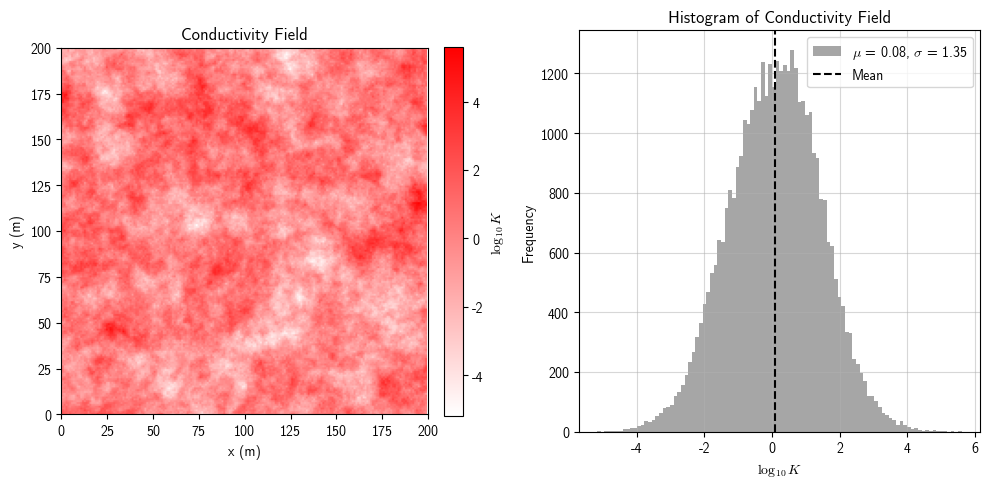

In [51]:
# logk_field = fbm_gen.sample()
logk_field = np.load(f'/project2/fbarros_324/binhaoli/task8_rMin_tMin/FastMarchingMethod/run{run}/std_{std}/lengthScale{length_scale}_size{num_pt}/logk_field/logKField_size{num_pt}_mc{mc}.npy')
log10k_field = np.log10(np.exp(logk_field))

fig, ax = plt.subplots(1, 2, figsize=(10,6))
ax = ax.ravel()
cmap = bwr_cmap(log10k_field, vcenter=min(log10k_field.flatten())+1e-10)
im = ax[0].imshow(log10k_field, cmap=cmap, origin="lower")
fig.colorbar(im, ax=ax[0], label='$\\log_{10} K$', fraction=0.046, pad=0.04)
ax[0].set_xlim([x[0], x[-1]+1])
ax[0].set_ylim([y[0], y[-1]+1])
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_title('Conductivity Field')

# Plot a histogram of the ln-K field
std_logk = np.std(log10k_field.flatten())
mean_logk = np.mean(log10k_field.flatten())
ax[1].hist(log10k_field.flatten(), bins=100, color='gray', alpha=0.7, label=f'$\\mu$ = {mean_logk:.2f}, $\\sigma$ = {std_logk:.2f}')
ax[1].set_title('Histogram of Conductivity Field')
ax[1].set_xlabel('$\\log_{10} K$')
ax[1].set_ylabel('Frequency')
ax[1].axvline(mean_logk, color='black', linestyle='--', label='Mean')
ax[1].legend()
ax[1].grid(True, alpha=0.5)
ax[1].set_box_aspect(1)

plt.tight_layout()
plt.show()

## Velocity field with PETSc

In [52]:
# --- assume you already have h and K ---
h, msg = solve_head(np.exp(logk_field), x, y, dh=1.0, rtol=1e-10, atol=1e-20, max_it=10000)
print(msg)

vx, vy = compute_velocity(np.exp(logk_field), x, y, h)


ConvergedReason: 2, Iterations: 13, Residual: 1.891e-09


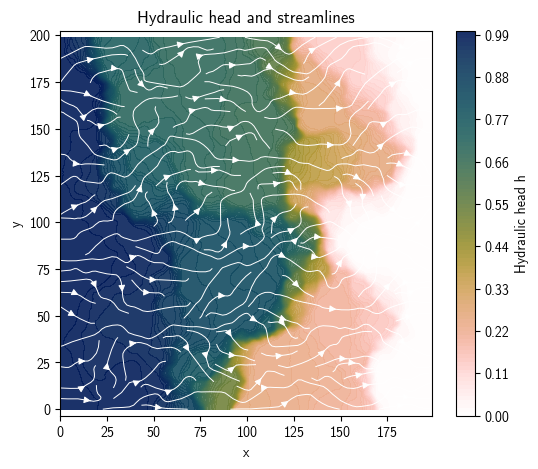

In [53]:
X, Y = np.meshgrid(x, y, indexing='xy')
plt.figure(figsize=(6,5))
plt.streamplot(X, Y, vx, vy, color='white', density=1.2, linewidth=0.7)
cont = plt.contourf(X, Y, h, levels=100, alpha=0.9, cmap=cm.batlowW.reversed())
plt.colorbar(cont, label='Hydraulic head h')
plt.title("Hydraulic head and streamlines")
plt.xlabel("x")
plt.ylabel("y")
plt.axis('equal')
plt.show()

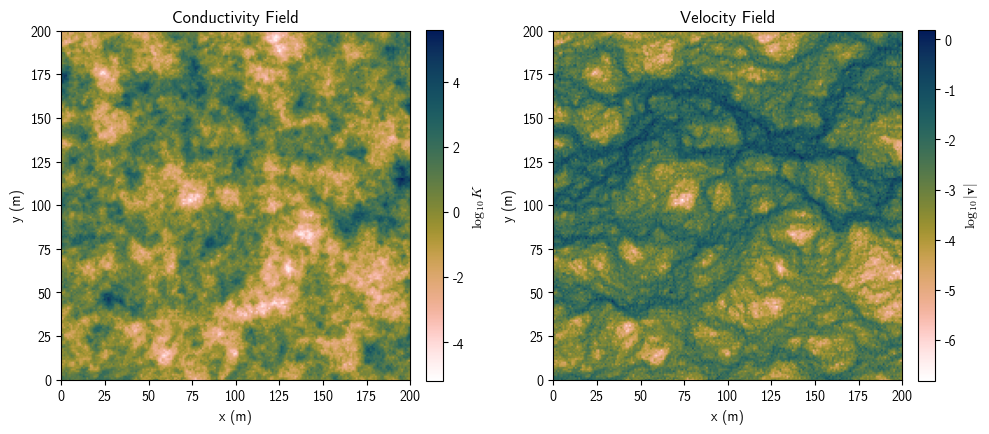

In [54]:
v_mag = np.sqrt(vx**2 + vy**2)
v_mag_positive = v_mag.copy()
v_mag_positive[v_mag_positive == 0] = np.unique(v_mag.flatten())[1]
v_mag_log = np.log10(v_mag_positive)
cmap = bwr_cmap(v_mag_log, vcenter=min(v_mag_log.flatten()))

fig, ax = plt.subplots(1, 2, figsize=(10,6))
ax = ax.ravel()
cmap = bwr_cmap(log10k_field, vcenter=min(log10k_field.flatten())+1e-10)
im = ax[0].imshow(log10k_field, origin="lower", cmap=cm.batlowW.reversed())
fig.colorbar(im, ax=ax[0], label='$\\log_{10} K$', fraction=0.046, pad=0.04)
ax[0].set_xlim([x[0], x[-1]+1])
ax[0].set_ylim([y[0], y[-1]+1])
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_title('Conductivity Field')

im = ax[1].imshow(v_mag_log, origin='lower', cmap=cm.batlowW.reversed())
fig.colorbar(im, ax=ax[1], label='$\\log_{10} |\\mathbf{v}|$', fraction=0.046, pad=0.04)
# ax[1].streamplot(x, y, vx, vy, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
ax[1].set_title(f'Velocity Field')
ax[1].set_xlabel('x (m)')
ax[1].set_ylabel('y (m)')
ax[1].set_xlim(x[0], x[-1]+1)
ax[1].set_ylim(y[0], y[-1]+1)

plt.tight_layout()
plt.show()

## Particle tracking

In [55]:
# Seeds for source
nP = 10000
x_s = source_vertex[0][0]
y_s0 = source_vertex[0][1]
y_s1 = source_vertex[1][1]
x_t = target_vertex[0][0]

seeds_x = np.full(nP, x_s, np.float32)
seeds_y = np.linspace(y_s0, y_s1, nP).astype(np.float32)

In [56]:
ds_max = 0.5 * min(np.min(np.diff(x)), np.min(np.diff(y)))
ds_min = 1e-20
px, py, pt, L, st, info_code, info_value, info_speed = gpu_track_particles_arclength(
    x, y, vx, vy, seeds_x, seeds_y,
    right_x=x_t,
    eps_speed=1e-30, 
    ds_min=ds_min, 
    ds_max=ds_max, 
    tol=1e-4,
    y_policy="stop",
    max_points=10000, 
    max_iters=1000000,
    threads_per_block=256, 
    dtype=np.float64
)

# Example: keep only successful trajectories (status==0)
ok = (st == 0)
print(f"Successful: {ok.sum()}/{nP}, mean points {np.mean(L[ok]) if ok.any() else 0:.1f}")

Successful: 10000/10000, mean points 1919.9


In [57]:
from collections import Counter

# Map of primary status codes → human-readable messages
status_labels = {
    0: "0: success (reached right boundary)",
    1: "1: stagnation (|v| < eps_speed)",
    2: "2: left x-domain",
    3: "3: left y-domain"
}

# Count each status
counts = Counter(st.tolist())

# Optional total
print(f"\nTotal particles: {len(st)}")

# Print the text label and count
print("\nPrimary particle outcomes:")
for code, count in counts.items():
    label = status_labels.get(code, f"4: other errors ({code})")
    print(f"{label:<40} {count:6d}")

# For additional info
print("\nAdditional info:")
for code, label in {
    4: "ds < ds_min",
    5: "ds > ds_max",
    6: "error > tol",
    7: "hit max_points",
    8: "hit max_iters",
    9: "NaN/Inf"
}.items():
    n = np.count_nonzero(info_code == code)
    if n:
        print(f"{label:20s}: {n}")



Total particles: 10000

Primary particle outcomes:
0: success (reached right boundary)       10000

Additional info:
ds > ds_max         : 48
error > tol         : 1857


Fastest particle: #6538, travel time = 3985.65 (units of time)


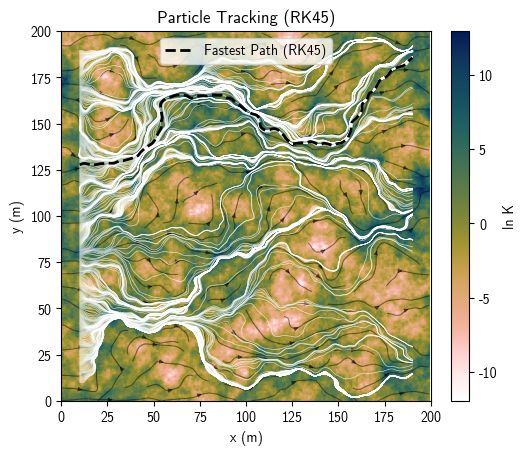

In [58]:
res = fastest_trajectory(px, py, pt, L, st)
print(f"Fastest particle: #{res['particle_id']}, travel time = {res['travel_time']:.6g} (units of time)")

fig, ax = plt.subplots()
im = ax.imshow(logk_field, origin='lower', cmap=cm.batlowW.reversed())
plt.colorbar(im, ax=ax, label='ln K', fraction=0.046, pad=0.04)
# ax.plot(source[:,0], source[:,1], 'k-')
# ax.plot(target[:,0], target[:,1], 'k-')
ax.streamplot(x, y, vx, vy, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
for i in range(0, nP, 20):  # plot 1 of every 20 particles
    curve_flow, = ax.plot(px[i, :L[i]], py[i, :L[i]], 'w-', lw=0.5, alpha=0.7)
ax.plot(res["x"], res["y"], 'k--', lw=2, label="Fastest Path (RK45)")
ax.set_title(f'Particle Tracking (RK45)')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_xlim(x[0], x[-1]+1)
ax.set_ylim(y[0], y[-1]+1)
ax.legend()
plt.show()

## Fastest path (isotropic case)

### Dijkstra

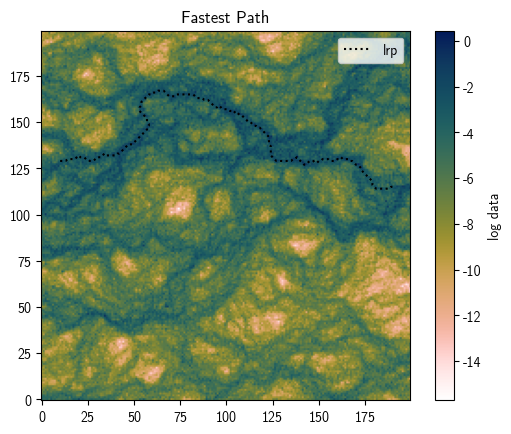

In [59]:
import matplotlib.pyplot as plt

data = v_mag
average_scheme = 'arithmetic'

start = [(y, source_vertex[0][0]) for y in range(source_vertex[0][1], source_vertex[1][1])]
end = [(y, target_vertex[0][0]) for y in range(0, num_pt-1)]

# path_grad, total_R, s_node, e_node, Rmap = dijkstra_2d_least_resistance(K, start, end, average=average_scheme, grad_scale=100, turn_penalty=0) #, average='arithmetic' or 'harmonic' 
fp_dijkstra, total_t, s_node, e_node, Rmap = dijkstra_2d_least_resistance(data, start, end, average=average_scheme, grad_scale=0, turn_penalty= 0) #, average='arithmetic' or 'harmonic' 

plt.imshow(np.log(data), origin='lower', cmap=cm.batlowW.reversed())
plt.plot([p[1] for p in fp_dijkstra], [p[0] for p in fp_dijkstra], 'k:', lw=1.5, label='lrp')
plt.title(f"Fastest Path")
plt.colorbar(label='log data')
plt.legend()
plt.show()

### FMM

/tmp/SLURM_6044962/ipykernel_2424696/3498751848.py:234: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(T), origin="lower")


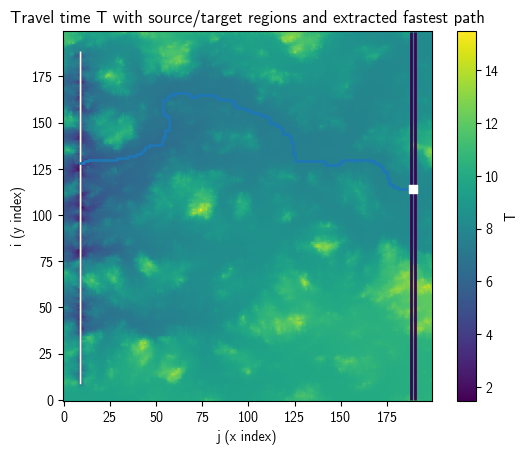

In [88]:
import numpy as np
import heapq
import math

FAR, NARROW, ACCEPTED = 0, 1, 2

def _solve_quadratic_update(ax, ay, f, h):
    """
    Upwind isotropic update for |∇T| = f (where f = 1/c).
    """
    if ax > ay:
        ax, ay = ay, ax
    fh = f * h

    if (ay - ax) >= fh:
        return ax + fh

    disc = 2.0 * fh * fh - (ay - ax) * (ay - ax)
    if disc < 0:
        disc = 0.0
    return 0.5 * (ax + ay + math.sqrt(disc))


def fast_marching_2d_regions(speed, source_mask, h=1.0):
    """
    Solve |∇T| = 1/c for isotropic medium with FMM, with T=0 on source_mask.

    Parameters
    ----------
    speed : (n,n) array, positive speeds c(x,y)>0
    source_mask : (n,n) bool array, True where source region is
    h : float, grid spacing

    Returns
    -------
    T : (n,n) travel time field
    state : (n,n) int8, FAR/NARROW/ACCEPTED (useful for debugging)
    """
    speed = np.asarray(speed, dtype=float)
    if speed.ndim != 2 or speed.shape[0] != speed.shape[1]:
        raise ValueError("speed must be a square 2D array (n x n).")
    if np.any(speed <= 0):
        raise ValueError("All speed values must be > 0.")

    n = speed.shape[0]
    source_mask = np.asarray(source_mask, dtype=bool)
    if source_mask.shape != (n, n):
        raise ValueError("source_mask must have same shape as speed.")
    if not np.any(source_mask):
        raise ValueError("source_mask is empty (no True entries).")

    f = 1.0 / speed  # slowness

    T = np.full((n, n), np.inf, dtype=float)
    state = np.full((n, n), FAR, dtype=np.int8)
    heap = []

    def push(i, j, val):
        if val < T[i, j]:
            T[i, j] = val
            heapq.heappush(heap, (val, i, j))
            state[i, j] = NARROW

    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # 1) Initialize: accept all source cells with T=0
    src_idx = np.argwhere(source_mask)
    for i, j in src_idx:
        T[i, j] = 0.0
        state[i, j] = ACCEPTED

    # 2) Initialize narrow band from source boundary
    for i, j in src_idx:
        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if 0 <= ni < n and 0 <= nj < n and state[ni, nj] != ACCEPTED:
                # update (ni, nj) using accepted neighbors
                ax = np.inf
                ay = np.inf

                # x-dir neighbors
                if nj - 1 >= 0 and state[ni, nj - 1] == ACCEPTED:
                    ax = min(ax, T[ni, nj - 1])
                if nj + 1 < n and state[ni, nj + 1] == ACCEPTED:
                    ax = min(ax, T[ni, nj + 1])

                # y-dir neighbors
                if ni - 1 >= 0 and state[ni - 1, nj] == ACCEPTED:
                    ay = min(ay, T[ni - 1, nj])
                if ni + 1 < n and state[ni + 1, nj] == ACCEPTED:
                    ay = min(ay, T[ni + 1, nj])

                if np.isinf(ax) and np.isinf(ay):
                    continue

                newT = _solve_quadratic_update(ax, ay, f[ni, nj], h)
                push(ni, nj, newT)

    # 3) Main FMM loop
    while heap:
        t, i, j = heapq.heappop(heap)
        if state[i, j] == ACCEPTED:
            continue
        state[i, j] = ACCEPTED
        T[i, j] = t

        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if not (0 <= ni < n and 0 <= nj < n):
                continue
            if state[ni, nj] == ACCEPTED:
                continue

            ax = np.inf
            ay = np.inf

            if nj - 1 >= 0 and state[ni, nj - 1] == ACCEPTED:
                ax = min(ax, T[ni, nj - 1])
            if nj + 1 < n and state[ni, nj + 1] == ACCEPTED:
                ax = min(ax, T[ni, nj + 1])

            if ni - 1 >= 0 and state[ni - 1, nj] == ACCEPTED:
                ay = min(ay, T[ni - 1, nj])
            if ni + 1 < n and state[ni + 1, nj] == ACCEPTED:
                ay = min(ay, T[ni + 1, nj])

            if np.isinf(ax) and np.isinf(ay):
                continue

            newT = _solve_quadratic_update(ax, ay, f[ni, nj], h)
            push(ni, nj, newT)

    return T, state


def extract_path_source_to_target(T, source_mask, target_mask, max_steps=200000):
    """
    Backtrack from the best target cell (min T over target_mask) to the source region
    by descending T on the 4-neighborhood.

    Returns
    -------
    path : list of (i,j) indices from target -> source (you can reverse if you want)
    chosen_target : (i,j)
    """
    T = np.asarray(T, dtype=float)
    n = T.shape[0]
    source_mask = np.asarray(source_mask, dtype=bool)
    target_mask = np.asarray(target_mask, dtype=bool)
    if target_mask.shape != (n, n) or source_mask.shape != (n, n):
        raise ValueError("source_mask and target_mask must match T shape.")
    if not np.any(target_mask):
        raise ValueError("target_mask is empty (no True entries).")

    # choose target with minimal T
    Ti = T.copy()
    Ti[~target_mask] = np.inf
    flat = np.argmin(Ti)
    ti = Ti.flat[flat]
    if not np.isfinite(ti):
        raise RuntimeError("No reachable target cell (T=inf on target_mask).")

    i, j = np.unravel_index(flat, T.shape)
    chosen_target = (i, j)

    path = [(i, j)]
    nbrs = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for _ in range(max_steps):
        if source_mask[i, j]:
            break

        best_val = T[i, j]
        best_ij = (i, j)

        for di, dj in nbrs:
            ni, nj = i + di, j + dj
            if 0 <= ni < n and 0 <= nj < n:
                if T[ni, nj] < best_val:
                    best_val = T[ni, nj]
                    best_ij = (ni, nj)

        if best_ij == (i, j):
            # can't descend further (plateau or discretization issue)
            break

        i, j = best_ij
        path.append((i, j))

    return path, chosen_target


# ----------------------------
# Example usage
# ----------------------------
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    n = num_pt
    l = num_pt
    h = l / (n - 1)

    # rng = np.random.default_rng(1)
    # base = rng.normal(size=(n, n))
    # speed = np.exp(0.25 * base)
    # for _ in range(20):
    #     speed = 0.25 * (np.roll(speed, 1, 0) + np.roll(speed, -1, 0) +
    #                     np.roll(speed, 1, 1) + np.roll(speed, -1, 1))

    # # Add a fast "channel" to make the path visually interesting
    # rr = np.arange(n)
    # channel_center = (0.55 * n + 0.15 * n * np.sin(2*np.pi*rr/n)).astype(int)
    # for i in range(n):
    #     c = channel_center[i]
    #     speed[max(0, c-2):min(n, c+3), i] *= 2.5  # faster band

    speed = v_mag

    # Define source region: a small square on the left-middle
    source_mask = np.zeros((n, n), dtype=bool)
    source_mask[y_s0:y_s1, x_s] = True

    # Define target region: a small square on the right-middle
    target_mask = np.zeros((n, n), dtype=bool)
    target_mask[:, x_t] = True

    T, _ = fast_marching_2d_regions(speed, source_mask, h=h)
    fp_fmm, chosen_target = extract_path_source_to_target(T, source_mask, target_mask)

    pi = np.array([p[0] for p in fp_fmm])
    pj = np.array([p[1] for p in fp_fmm])

    plt.figure()
    plt.imshow(np.log(T), origin="lower")
    plt.colorbar(label="T")
    plt.contour(source_mask.astype(float), levels=[1], linewidths=2)
    plt.contour(target_mask.astype(float), levels=[0], linewidths=2)
    plt.plot(pj, pi, linewidth=2)
    plt.scatter([chosen_target[1]], [chosen_target[0]], s=30)
    plt.scatter(fp_fmm[0][1], fp_fmm[0][0], marker='s', color='white', zorder=3)
    plt.title("Travel time T with source/target regions and extracted fastest path")
    plt.xlabel("j (x index)")
    plt.ylabel("i (y index)")
    plt.show()


## LRP

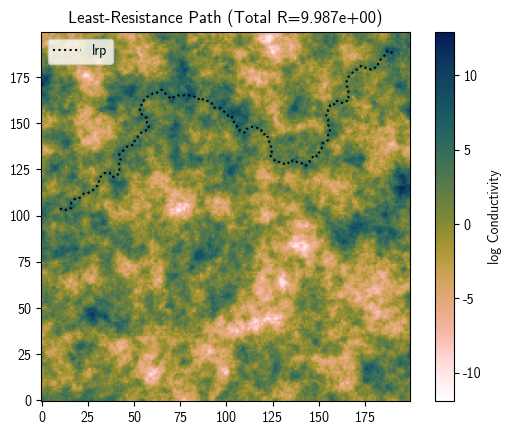

In [61]:
import matplotlib.pyplot as plt


K = np.exp(logk_field).astype(np.longdouble)
average_scheme = 'harmonic'

start = [(y, source_vertex[0][0]) for y in range(source_vertex[0][1], source_vertex[1][1])]
end = [(y, target_vertex[0][0]) for y in range(0, num_pt-1)]

# path_grad, total_R, s_node, e_node, Rmap = dijkstra_2d_least_resistance(K, start, end, average=average_scheme, grad_scale=100, turn_penalty=0) #, average='arithmetic' or 'harmonic' 
lrp, total_R, s_node, e_node, Rmap = dijkstra_2d_least_resistance(K, start, end, average='harmonic', grad_scale=0, turn_penalty= 0) #, average='arithmetic' or 'harmonic' 

plt.imshow(logk_field, origin='lower', cmap=cm.batlowW.reversed())
# plt.plot([p[1] for p in lrp_grad], [p[0] for p in lrp_grad], 'k-', lw=1.5, label='lrp with grad')
plt.plot([p[1] for p in lrp], [p[0] for p in lrp], 'k:', lw=1.5, label='lrp')
plt.title(f"Least-Resistance Path (Total R={total_R:.3e})")
plt.colorbar(label='log Conductivity')
plt.legend()
plt.show()


## Comparison

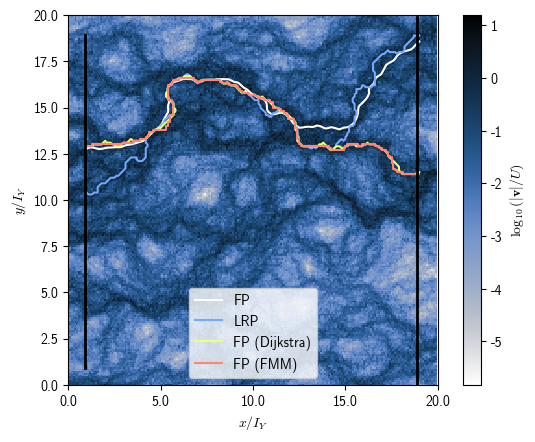

In [62]:
import matplotlib.ticker as ticker

size = 200
K_G = 1 # geometric mean of hydraulic conductivity
I_Y = 0.05 * size
q_ref = K_G * dh
t_ref = I_Y / q_ref

x_s = size // 20 - 1
y_s0 = size // 20 - 1
y_s1 = size - size//20 - 1
x_t = size - size//20 - 1

fig, ax = plt.subplots()
pcm = ax.pcolormesh(x, y, np.log10(v_mag/q_ref), shading="auto", cmap=cm.oslo.reversed())
fig.colorbar(pcm, ax=ax, label=r'$\log_{10} (|\mathbf{v}| / U)$')
ax.plot(res["x"], res["y"], color='white', ls='-', lw=1.5, label="FP")
ax.plot([p[1] for p in lrp], [p[0] for p in lrp], color='#75A9FF', ls='-', lw=1.5, label='LRP')
ax.plot([p[1] for p in fp_dijkstra], [p[0] for p in fp_dijkstra], color='#EFFF75', ls='-', lw=1.5, label='FP (Dijkstra)')
ax.plot(pj, pi, color='#FF8575', ls='-', lw=1.5, label='FP (FMM)')
ax.plot([x_s, x_s], [y_s0, y_s1], 'k-', alpha=1, linewidth=2)
ax.plot([x_t, x_t], [0, size-1], 'k-', alpha=1, linewidth=2)
ax.set_xlabel(r"$x/I_Y$")
ax.set_ylabel(r"$y/I_Y$")
# ax.set_title(f"Fastest Path")
ax.set_xlim(0, 200+1e-9)
ax.set_ylim(0, 200+1e-9)
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: x / I_Y)
)
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda y, _: y / I_Y)
)
ax.set_aspect('equal', adjustable='box')
ax.legend()

# plt.savefig(f'paths_std{std}.png', dpi=300, bbox_inches="tight")
plt.show()

## Finsler

In [63]:
import numpy as np
import heapq

FAR, NARROW, ACCEPTED = 0, 1, 2


def randers_cost(u, M, b, eps=1e-12):
    """
    Randers metric (cost for displacement u):
        F(u) = sqrt(u^T M u) - b · u

    Requirements (for positivity for all u != 0):
        ||b||_{M^{-1}} < 1
    """
    # symmetric part
    q = u @ (M @ u)
    if q <= 0:
        return np.inf
    sym = np.sqrt(q)

    # asymmetric drift part
    asym = b @ u

    val = sym - asym
    # In a valid Randers metric this should be > 0 for u != 0.
    # We clamp to avoid negative/zero numerical issues; if you see many clamps,
    # your b is too large relative to M.
    if val <= eps:
        return eps
    return val


def make_square_stencil(radius=2, include_diagonals=True):
    """
    Integer-step stencil: all (di,dj) with max(|di|,|dj|) <= radius.
    This is easy and robust; increase radius to resolve stronger anisotropy.
    """
    steps = []
    for di in range(-radius, radius + 1):
        for dj in range(-radius, radius + 1):
            if di == 0 and dj == 0:
                continue
            if not include_diagonals and (di != 0 and dj != 0):
                continue
            steps.append((di, dj))
    return steps


def dijkstra_randers_2d(
    M_field,          # (n,n,2,2) SPD tensor field
    b_field,          # (n,n,2) drift field
    source_mask,      # (n,n) bool
    h=1.0,
    stencil_radius=2,
):
    """
    Solve Randers 'distance'/travel-time from source region on a grid via directed Dijkstra.

    M_field: SPD matrix field. For isotropic speed c(x): M = (1/c^2) I.
    b_field: drift field (asymmetric). Must satisfy ||b||_{M^{-1}} < 1 at each cell (roughly).
    """
    M_field = np.asarray(M_field, dtype=float)
    b_field = np.asarray(b_field, dtype=float)
    source_mask = np.asarray(source_mask, dtype=bool)

    if M_field.ndim != 4 or M_field.shape[-2:] != (2, 2):
        raise ValueError("M_field must have shape (n,n,2,2).")
    if b_field.shape[:2] != M_field.shape[:2] or b_field.shape[-1] != 2:
        raise ValueError("b_field must have shape (n,n,2).")
    n, m = M_field.shape[0], M_field.shape[1]
    if n != m:
        raise ValueError("Grid must be square for this helper (n x n).")
    if source_mask.shape != (n, n) or not np.any(source_mask):
        raise ValueError("source_mask must be (n,n) and non-empty.")

    steps = make_square_stencil(radius=stencil_radius, include_diagonals=True)

    T = np.full((n, n), np.inf, dtype=float)
    state = np.full((n, n), FAR, dtype=np.int8)

    # predecessor pointers for path extraction
    # pred_i[i,j], pred_j[i,j] gives previous cell on best-known path
    pred_i = np.full((n, n), -1, dtype=np.int32)
    pred_j = np.full((n, n), -1, dtype=np.int32)

    heap = []

    # initialize sources
    src_idx = np.argwhere(source_mask)
    for i, j in src_idx:
        T[i, j] = 0.0
        state[i, j] = NARROW
        heapq.heappush(heap, (0.0, i, j))

    while heap:
        t, i, j = heapq.heappop(heap)
        if state[i, j] == ACCEPTED:
            continue
        if t != T[i, j]:
            # stale heap entry
            continue

        state[i, j] = ACCEPTED

        Mi = M_field[i, j]
        bi = b_field[i, j]

        for di, dj in steps:
            ni, nj = i + di, j + dj
            if not (0 <= ni < n and 0 <= nj < n):
                continue
            if state[ni, nj] == ACCEPTED:
                # still allow relaxation even if accepted? In Dijkstra, accepted is final.
                # So skip.
                continue

            # physical displacement vector u (x corresponds to column, y to row)
            # Here we treat grid indices (i,j) as (y,x). So u = (dx, dy) = (dj*h, di*h).
            u = np.array([dj * h, di * h], dtype=float)

            w = randers_cost(u, Mi, bi)
            newT = t + w

            if newT < T[ni, nj]:
                T[ni, nj] = newT
                pred_i[ni, nj] = i
                pred_j[ni, nj] = j
                state[ni, nj] = NARROW
                heapq.heappush(heap, (newT, ni, nj))

    return T, state, (pred_i, pred_j)


def extract_path_with_predecessor(T, pred, source_mask, target_mask):
    """
    Extract path using predecessor pointers (more reliable than greedy descent).
    Chooses best target cell (min T over target_mask) and follows pred back.
    """
    T = np.asarray(T, dtype=float)
    source_mask = np.asarray(source_mask, dtype=bool)
    target_mask = np.asarray(target_mask, dtype=bool)
    pred_i, pred_j = pred

    n = T.shape[0]
    if target_mask.shape != (n, n) or not np.any(target_mask):
        raise ValueError("target_mask must be (n,n) and non-empty.")

    Ti = T.copy()
    Ti[~target_mask] = np.inf
    flat = np.argmin(Ti)
    if not np.isfinite(Ti.flat[flat]):
        raise RuntimeError("No reachable target cell (T=inf on target_mask).")

    i, j = np.unravel_index(flat, T.shape)
    chosen_target = (i, j)

    path = [(i, j)]
    # follow predecessors back
    while not source_mask[i, j]:
        pi, pj = pred_i[i, j], pred_j[i, j]
        if pi < 0:
            break
        i, j = int(pi), int(pj)
        path.append((i, j))

    return path, chosen_target

In [64]:
# import numpy as np

# def build_M0_from_control(v_field, c0=1.0, anis_ratio=0.4, eps=1e-12):
#     """
#     M0 = (AA^T)^{-1} where A defines control speeds
#     """
#     v = np.asarray(v_field, float)
#     n, m, _ = v.shape
#     M0 = np.zeros((n, m, 2, 2), float)

#     for i in range(n):
#         for j in range(m):
#             vx, vy = v[i, j]
#             s = np.hypot(vx, vy)

#             if s < eps:
#                 # isotropic control
#                 M0[i,j] = np.eye(2) / c0**2
#                 continue

#             ex, ey = vx/s, vy/s
#             px, py = -ey, ex

#             R = np.array([[ex, px],
#                           [ey, py]])

#             c_para = c0
#             c_perp = anis_ratio * c0

#             D = np.diag([1/c_para**2, 1/c_perp**2])
#             M0[i,j] = R @ D @ R.T

#     return M0

# def build_b_from_drift(M0, v_field, kappa=0.7, eps=1e-12):
#     """
#     b = alpha * M0 * v
#     with ||b||_{M0^{-1}} = kappa < 1
#     """
#     v = np.asarray(v_field, float)
#     n, m, _ = v.shape
#     b = np.zeros((n, m, 2), float)

#     for i in range(n):
#         for j in range(m):
#             M = M0[i,j]
#             vv = v[i,j]

#             denom = np.sqrt(max(vv @ (M @ vv), 0.0)) + eps
#             alpha = kappa / denom

#             b[i,j] = alpha * (M @ vv)

#     return b

def randers_r_of_theta(M, b, theta):
    d = np.stack([np.cos(theta), np.sin(theta)], axis=0)  # (2, K)
    # compute sqrt(d^T M d) for each theta
    Md = M @ d                         # (2, K)
    quad = np.sum(d * Md, axis=0)      # (K,)
    sym = np.sqrt(np.maximum(quad, 0))

    asym = b @ d                       # (K,)
    denom = sym - asym                 # (K,)

    # denom must be > 0 for a valid Randers indicatrix in that direction
    # mask invalid directions (can happen if b is too strong)
    valid = denom > 1e-12
    r = np.empty_like(denom)
    r[valid] = 1.0 / denom[valid]
    r[~valid] = np.nan
    return r, valid

def plot_randers_indicatrix(M, b, K=720, ax=None, show_vectors=True):
    theta = np.linspace(0, 2*np.pi, K, endpoint=False)
    r, valid = randers_r_of_theta(M, b, theta)

    x = r * np.cos(theta)
    y = r * np.sin(theta)

    if ax is None:
        fig, ax = plt.subplots()

    ax.plot(x, y)
    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title("Randers indicatrix: F(u)=1")

    if show_vectors:
        ax.quiver(0, 0, b[0], b[1], angles="xy", scale_units="xy", scale=1, width=0.003)
        # optionally plot principal directions of M^{-1} as "fast axes" (not required)

    # report invalid angles if any
    frac_invalid = np.mean(~valid)
    if frac_invalid > 0:
        ax.text(0.02, 0.98, f"Invalid directions: {100*frac_invalid:.1f}%",
                transform=ax.transAxes, va="top")

    return ax

import numpy as np

def build_randers_from_W(
    W_field,                 # (n,n,2) vector field
    perp_ratio=0.5,          # in (0,1]: sideways speed = perp_ratio * |W|
    back_factor=2.0,         # >=1: backward speed = |W| / back_factor
    min_speed=1e-6,          # floor for |W| to avoid divide-by-zero
    isotropic_only=False     # if True: returns pure isotropic metric (b=0, M=I/|W|^2)
):
    """
    Construct Randers metric F(u)=sqrt(u^T M u) - b·u from a given velocity field W(x),
    such that:
      - baseline isotropic speed is c(x)=|W(x)|
      - when isotropic_only=True => M=I/c^2 and b=0 exactly
      - otherwise, we enforce:
            c_eff(+e) = |W|
            c_eff(-e) = |W|/back_factor
            c_eff(perp) = perp_ratio*|W|
        where e = W/|W| and c_eff(d)=1/F(d) for unit direction d.

    Returns:
      c_iso : (n,n)  baseline speed c(x)=|W| (floored by min_speed)
      M     : (n,n,2,2)
      b     : (n,n,2)
      e     : (n,n,2) unit direction W/|W| (arbitrary where |W|~0)
    """
    W = np.asarray(W_field, dtype=float)
    if W.ndim != 3 or W.shape[-1] != 2:
        raise ValueError("W_field must have shape (n,n,2).")

    n, m, _ = W.shape

    s = np.linalg.norm(W, axis=2)                   # |W|
    c_iso = np.maximum(s, float(min_speed))         # baseline isotropic speed

    # Allocate
    M = np.zeros((n, m, 2, 2), dtype=float)
    b = np.zeros((n, m, 2), dtype=float)
    e = np.zeros((n, m, 2), dtype=float)

    # Validate knobs
    if not (0.0 < perp_ratio <= 1.0):
        raise ValueError("perp_ratio must be in (0,1].")
    if back_factor < 1.0:
        raise ValueError("back_factor must be >= 1.")

    # If you want the isotropic approximation exactly:
    if isotropic_only:
        for i in range(n):
            for j in range(m):
                c = c_iso[i, j]
                M[i, j] = np.eye(2) / (c * c)
                b[i, j] = 0.0
                # direction (just for reference)
                if s[i, j] > 0:
                    e[i, j] = W[i, j] / s[i, j]
                else:
                    e[i, j] = np.array([1.0, 0.0])
        return c_iso, M, b, e

    # Otherwise: anisotropic + asymmetric refinement
    for i in range(n):
        for j in range(m):
            c = c_iso[i, j]

            # unit direction e = W/|W|
            if s[i, j] > 0:
                ex, ey = W[i, j] / s[i, j]
            else:
                # arbitrary if |W|=0 (metric reverts to isotropic-ish via c_iso floor)
                ex, ey = 1.0, 0.0
            e[i, j] = np.array([ex, ey])

            # perpendicular direction
            px, py = -ey, ex

            # rotation matrix R = [e, e_perp]
            R = np.array([[ex, px],
                          [ey, py]], dtype=float)

            # Target directional speeds
            c_plus  = c                       # max speed along +e: |W|
            c_minus = c / back_factor          # reduced speed along -e
            c_perp  = perp_ratio * c           # reduced sideways speed

            # Choose Randers parameters to match c_plus and c_minus exactly.
            # For unit direction d:
            #   F(d) = sqrt(d^T M d) - b·d
            # Along +e: F(+e) = 1/c_plus
            # Along -e: F(-e) = 1/c_minus
            #
            # If we set (in the local (e, e_perp) frame):
            #   sqrt(d^T M d) gives 1/c_sym_para along ±e
            #   b·d = beta * (e·d) with b parallel to e
            #
            # Then:
            #   1/c_sym_para - beta = 1/c_plus
            #   1/c_sym_para + beta = 1/c_minus
            inv_csym_para = 0.5 * (1.0/c_plus + 1.0/c_minus)
            beta          = 0.5 * (1.0/c_minus - 1.0/c_plus)  # >=0 if c_minus<=c_plus

            c_sym_para = 1.0 / inv_csym_para
            c_sym_perp = c_perp  # keep perpendicular purely symmetric

            # Build symmetric tensor M (slowness^2 tensor)
            D = np.diag([1.0/(c_sym_para**2), 1.0/(c_sym_perp**2)])
            M[i, j] = R @ D @ R.T

            # Build b (covector) aligned with e
            b[i, j] = beta * np.array([ex, ey], dtype=float)

    return c_iso, M, b, e

In [65]:
def check_randers_condition(M0, b):
    n, m = b.shape[:2]
    vals = np.zeros((n,m), float)
    for i in range(n):
        for j in range(m):
            Minv = np.linalg.inv(M0[i,j])
            vals[i,j] = np.sqrt(b[i,j] @ (Minv @ b[i,j]))
    return vals  # should be < 1 everywhere

In [66]:
v = np.array([vx, vy])
v = v.transpose(1, 2, 0)

In [67]:
c_iso, M_field, b_field, e = build_randers_from_W(v, perp_ratio=0.1, back_factor=6.0, isotropic_only=False)

In [68]:
check_randers_condition(M_field, b_field)

array([[0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571],
       [0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571],
       [0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571],
       ...,
       [0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571],
       [0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571],
       [0.71428571, 0.71428571, 0.71428571, ..., 0.71428571, 0.71428571,
        0.71428571]], shape=(200, 200))

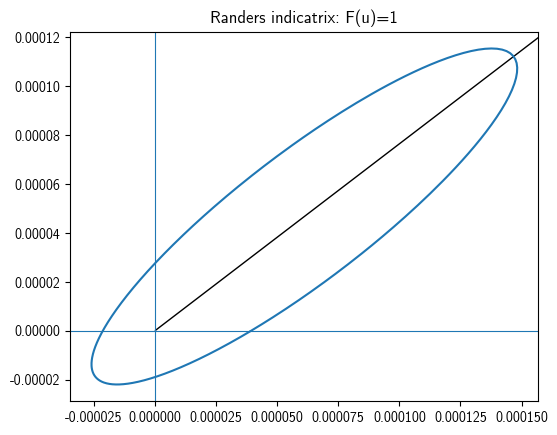

In [69]:
# Check indicatrix at one grid point (i,j)
i = 18
j = 45
plot_randers_indicatrix(M_field[i,j], b_field[i,j])
plt.show()

In [70]:
def randers_indicatrix_points(M, b, K=240, eps=1e-12):
    """
    Points u(theta) on indicatrix F(u)=1 for F(u)=sqrt(u^T M u)-b·u.
    u = r(theta) d(theta), r = 1/(sqrt(d^T M d) - b·d)
    """
    theta = np.linspace(0, 2*np.pi, K, endpoint=False)
    d = np.stack([np.cos(theta), np.sin(theta)], axis=0)  # (2,K)
    Md = M @ d
    quad = np.sum(d * Md, axis=0)
    sym = np.sqrt(np.maximum(quad, 0.0))
    asym = b @ d
    denom = sym - asym

    valid = denom > eps
    r = np.full_like(denom, np.nan, dtype=float)
    r[valid] = 1.0 / denom[valid]

    x = r * np.cos(theta)
    y = r * np.sin(theta)
    return x, y


def visualize_indicatrix_field(
    W_field,
    perp_ratio=0.5,
    back_factor=2.0,
    h=1.0,
    stride=10,
    K=180,
    glyph_scale=0.30,          # scales glyph size in plot units (~h)
    show_W_quiver=True,
    quiver_stride=None
):
    W = np.asarray(W_field, float)
    n, m, _ = W.shape

    c_iso, M_field, b_field, _ = build_randers_from_W(
        W, perp_ratio=perp_ratio, back_factor=back_factor
    )

    if quiver_stride is None:
        quiver_stride = stride

    fig, ax = plt.subplots()

    # Optional: plot W in the background
    if show_W_quiver:
        ys = np.arange(0, n, quiver_stride)
        xs = np.arange(0, m, quiver_stride)
        X, Y = np.meshgrid(xs * h, ys * h)
        U = W[ys[:, None], xs[None, :], 0]
        V = W[ys[:, None], xs[None, :], 1]
        v_mag_log = np.log10(np.sqrt(W[:,:,0]**2 + W[:,:,1]**2))
        # ax.quiver(X, Y, U, V, angles="xy", scale_units="xy", scale=None, width=0.0025)
        ax.streamplot(X, Y, U, V, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
        im = ax.imshow(v_mag_log, origin='lower', cmap=cm.batlowW.reversed())
        fig.colorbar(im, ax=ax, label='$\\log_{10} |\\mathbf{v}|$', fraction=0.046, pad=0.04)


    # Indicatrix glyphs
    for i in range(0, n, stride):
        for j in range(0, m, stride):
            M = M_field[i, j]
            b = b_field[i, j]
            xi, yi = j * h, i * h  # (x,y) from (j,i)

            gx, gy = randers_indicatrix_points(M, b, K=K)
            ax.plot(xi + glyph_scale * h * gx, yi + glyph_scale * h * gy, color='white', linewidth=0.8)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Randers indicatrix field (stride={stride}, perp_ratio={perp_ratio}, back_factor={back_factor})")
    plt.show()

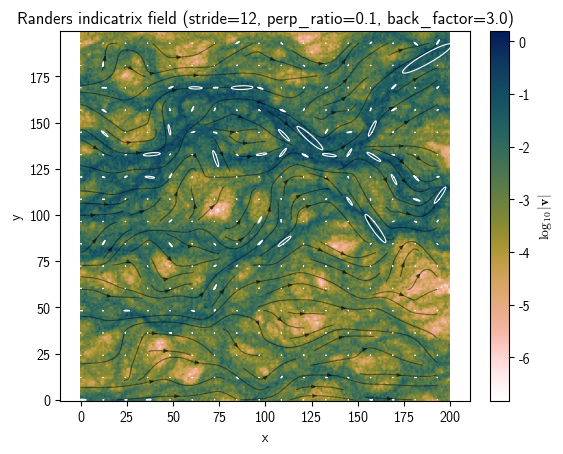

In [75]:
visualize_indicatrix_field(
    v,
    perp_ratio=0.1,     # sideways speed = 0.4|W|
    back_factor=3.0,    # backward speed = |W|/3
    h=h,
    stride=12,          # glyph every 12 cells
    glyph_scale=100,   # size of glyphs
    show_W_quiver=True
)

In [85]:
T, state, pred = dijkstra_randers_2d(
    M_field=M_field,
    b_field=b_field,
    source_mask=source_mask,
    h=h,
    stencil_radius=50   # increase if anisotropy is strong
)

In [86]:
path, chosen_target = extract_path_with_predecessor(
    T, pred, source_mask, target_mask
)

path = np.array(path[::-1])  # source → target

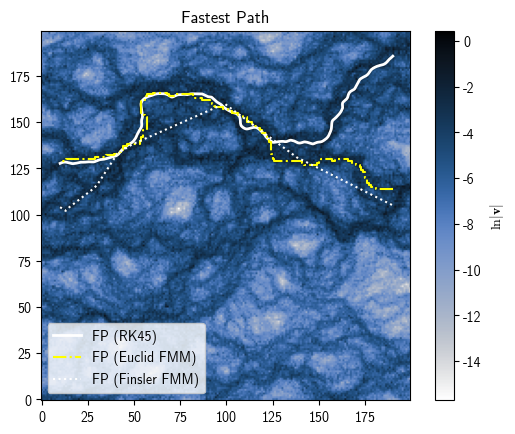

In [87]:
plt.imshow(np.log(v_mag), origin='lower', cmap=cm.oslo.reversed())
plt.plot(res["x"], res["y"], color='white', ls='-', lw=2, label="FP (RK45)")
# plt.plot([p[1] for p in path], [p[0] for p in path], color='red', ls='-', lw=1.5, label='FP (Dijkstra)')
# plt.plot([p[1] for p in lrp], [p[0] for p in lrp], color='yellow', ls='-', lw=1.5, label='LRP')
plt.plot(pj, pi, color='yellow', ls='-.', lw=1.5, label='FP (Euclid FMM)')
plt.plot(path[:,1], path[:,0], color='white', ls=':', label='FP (Finsler FMM)')
plt.title(f"Fastest Path")
plt.colorbar(label='$\\ln |\\mathbf{v}|$')
plt.legend()
plt.show()

## Visualize a single realization

NameError: name 'source' is not defined

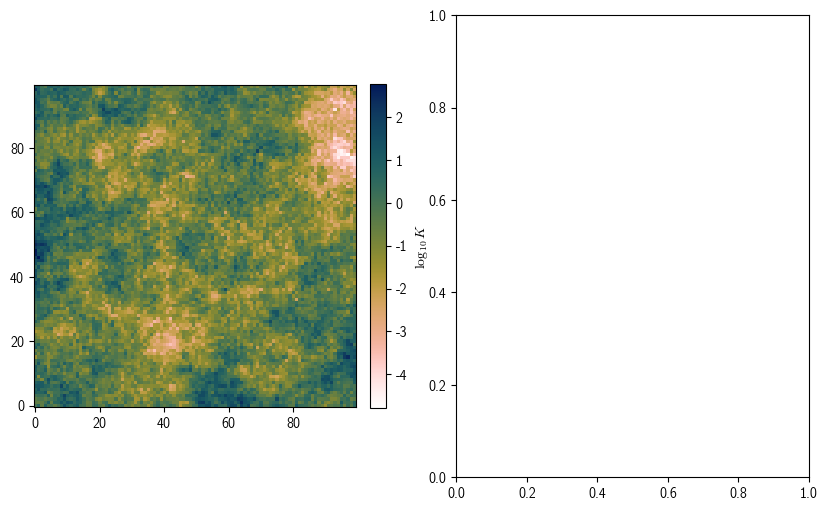

In [25]:

fig, ax = plt.subplots(1, 2, figsize=(10,6))
ax = ax.ravel()
cmap = bwr_cmap(log10k_field, vcenter=min(log10k_field.flatten())+1e-10)
im = ax[0].imshow(log10k_field, origin="lower", cmap=cm.batlowW.reversed())
fig.colorbar(im, ax=ax[0], label='$\\log_{10} K$', fraction=0.046, pad=0.04)
ax[0].plot(source[:,0], source[:,1], 'k-')
ax[0].plot(target[:,0], target[:,1], 'k-')
# ax[0].streamplot(x, y, vx, vy, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
ax[0].plot(res["x"], res["y"], 'k--', lw=2, label="Fastest Path (RK45)")
ax[0].plot([p[1] for p in path], [p[0] for p in path], 'w-', lw=1.5, label=f"my LRP")
# ax[0].plot([p[1] for p in path_grad], [p[0] for p in path_grad], 'w:', lw=1.5, label=f"my LRP with Grad")
ax[0].set_xlim([x[0], x[-1]+1])
ax[0].set_ylim([y[0], y[-1]+1])
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_title('Conductivity Field')
ax[0].legend()

im = ax[1].imshow(v_mag_log, origin='lower', cmap=cm.batlowW.reversed())
fig.colorbar(im, ax=ax[1], label='$\\log_{10} |\\mathbf{v}|$', fraction=0.046, pad=0.04)
ax[1].plot(source[:,0], source[:,1], 'k-')
ax[1].plot(target[:,0], target[:,1], 'k-')
# ax[1].streamplot(x, y, vx, vy, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
ax[1].plot(res["x"], res["y"], 'k--', lw=2, label="Fastest Path (RK45)")
# ax[1].plot([p[1] for p in path], [p[0] for p in path], 'w-', lw=1.5, label=f"my Least Resistance Path")
ax[1].set_title(f'Velocity Field')
ax[1].set_xlabel('x (m)')
ax[1].set_ylabel('y (m)')
ax[1].set_xlim(x[0], x[-1]+1)
ax[1].set_ylim(y[0], y[-1]+1)
ax[1].legend()

plt.tight_layout()
plt.show()

## Examine fields

In [11]:
lrp = np.loadtxt(path_lmoutput / "least_resistance_path.dat", delimiter=',')[:, :-1] - 0.5

fig, ax = plt.subplots()
im = ax.imshow(logk_field, origin='lower', cmap=cm.batlowW.reversed())
plt.colorbar(im, ax=ax, label='ln K', fraction=0.046, pad=0.04)
ax.plot(source[:,0], source[:,1], 'k-')
ax.plot(target[:,0], target[:,1], 'k-')
ax.streamplot(x, y, vx, vy, color=to_rgba('black', alpha=0.45), linewidth=0.8, arrowsize=0.6)
# for i in range(0, nP):  # plot 1 of every 20 particles
#     curve_flow, = ax.plot(px[i, :L[i]], py[i, :L[i]], 'w-', lw=0.5, alpha=0.7)
# for idx, traj in enumerate(debut_traj_list):
#     curve_debut, = ax.plot(traj[:,0], traj[:,1], color='#202020', linestyle='-')
# curve_debut.set_label(f'Fastest Path (PAR2)')
ax.plot(res["x"], res["y"], 'k--', lw=2, label="Fastest Path (RK45)")
ax.plot(lrp[:,0], lrp[:,1], 'k:', label=f"Least Resistance Path")
ax.plot([p[1] for p in path], [p[0] for p in path], 'w-', lw=1.5)
ax.set_title(f'Particle Tracking (RK45) (std(ln K)={std})')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_xlim(x[0], x[-1]+1)
ax.set_ylim(y[0], y[-1]+1)
ax.legend()
plt.show()

NameError: name 'path_lmoutput' is not defined

In [34]:
import pickle
with open("result.pkl", "rb") as f:
    result = pickle.load(f)

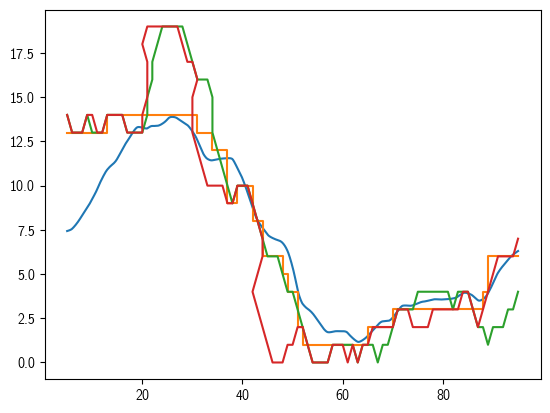

In [41]:
plt.plot(result['fp_rk45'][0][:,1], result['fp_rk45'][0][:,0])
plt.plot(result['fp_fmm'][0][:,1], result['fp_fmm'][0][:,0])
plt.plot(result['fp_dijkstra'][0][:,1], result['fp_dijkstra'][0][:,0])
plt.plot(result['lrp'][0][:,1], result['lrp'][0][:,0])
